# **Can Machine Learning Learn My Photographic Eye?**

## **Main Assignment**



**Main Assignment**

**1. Introduction, Research Question, and Hypotheses**

1.1 Motivation and Purpose

1.2 Research Question

1.3 Hypotheses

1.4 Experimental Overview

**2. Dataset and Experimental Design**

2.1 Photograph Collection and Eligibility

2.2 Sampling, Photography Sessions, and Portfolio Labels

2.3 Final Dataset and Evaluation Design

2.4 Dataset Limitations and Potential Biases

**3. Setting Up the Dataset**

3.1 Loading the Final Dataset

3.2 Preparing the Development and Test Sets

**4. Image Preprocessing**

4.1 Loading the Image Tools

4.2 Preparing the 64 × 64 Images

4.3 Checking the Processed Photograph

**5. Model Development and Cross-Validation**

5.1 Evaluating Models Using the Same Folds

5.2 Dummy Classifier and Raw-Pixel Logistic Regression

5.3 PCA + Logistic Regression

C2: PCA + Logistic Regression

5.4 Frozen ResNet18 Features + Logistic Regression

C3: Pretrained ResNet18 + Logistic Regression

5.5 Comparing All Four Models

**6. Final Evaluation on Berlin Photographs**

6.1 Training the Selected Model

6.2 Preparing the Berlin Photographs

6.3 Evaluating the Final Model

Interpreting the Berlin Results

6.4 Examining Classification Errors

6.5 Examining Individual Berlin Predictions

**7. Discussion, Limitations, and Future Improvements**

7.1 What Did I Learn?

7.2 Why Might Prediction Be Difficult?

7.3 How Could I Improve This Project?

**8. Appendix**


**9. References**


**10. AI Statement**


**NOTE: Resources**
1) This folder contains all the photos, metadata, and instructions on how to access the dataset to run the code for yourself: https://drive.google.com/drive/folders/1gmDHo0JDfF2qD9de_57G209mXdkD70Fl?usp=sharing

2) Here is the link to my Github repo: https://github.com/bukhari2005/CS156-Finding-Patterns-in-Data

## 1. Introduction, Research Question, and Hypotheses
### 1.1 Motivation and Purpose

Photography is one of my personal interests, and I have collected photographs across different countries during my travels. When reviewing these photographs, I usually decide which ones I would include in my portfolio and which ones I would leave out. Out of curiousity, I wanted to investigate whether these decisions follow consistent visual patterns. For example, do I tend to prefer certain compositions, colors, lighting conditions, or subjects? More importantly, I wanted to investigate whether a machine learning model could identify patterns in my previous selections and predict my choices for new photographs?
<br> <br>
I treated portfolio selection as a binary classification problem, where each photograph received one of two labels:

1 — Selected: A photograph I would consider worthy of including in my portfolio.

0 — Not selected: A photograph I would not include in my portfolio.
<br> <br>
These labels represent my personal judgment rather than an objective measure of photographic quality. My goal was not to determine whether a photograph is universally good or bad. Instead, I wanted to examine whether my selection decisions contain visual patterns that machine learning can identify.

### 1.2 Research Question

I want to investigate that to what extent can machine learning predict which of my photographs I would select for my portfolio, including photographs from a location not used during model development? I was super interested to know whether different ways of representing photographs affect prediction performance and whether the selected model could generalize beyond the locations used for development.

### 1.3 Hypotheses

I investigated three expectations:

H1 — Learning from photographs: I expected at least one model using visual information to achieve higher mean balanced accuracy than a dummy classifier that ignores image information. This would suggest that the photographs contain some information useful for predicting my selection decisions.
<br> <br>
H2 — Pretrained visual features: I expected pretrained ResNet18 features combined with logistic regression to outperform logistic regression using raw pixels or PCA-reduced pixels. ResNet18 is a convolutional neural network originally designed for image recognition. Its pretrained weights capture visual patterns learned from a large image dataset, which might help predict my selections despite my small dataset (He et al., 2016; PyTorch, n.d.).
<br> <br>
H3 — Generalization to an unseen location: I expected the selected model to achieve balanced accuracy above 0.50 on Berlin photographs. However, performance could be lower than during development because Berlin photographs might contain different subjects, lighting, compositions, or other visual characteristics.

### 1.4 Experimental Overview

To investigate these hypotheses, I created a labeled dataset of 100 original photographs from five locations, with 10 selected and 10 non-selected photographs per location. I used 80 photographs from Argentina, South Korea, Poland, and Taiwan for model development while the remaining 20 Berlin photographs were reserved for final evaluation.
<br> <br>
Then, I compared four approaches: a dummy classifier, logistic regression using raw pixels, PCA followed by logistic regression, and frozen pretrained ResNet18 features followed by logistic regression.  The four models were evaluated using the same three photography-session-aware cross-validation folds. I selected the model with the highest mean balanced accuracy, retrained its classifier using all 80 development photographs, and evaluated it once on Berlin. I also examined its correct and incorrect predictions to understand its limitations.
<br> <br>
The following diagram summarizes the complete workflow. Then, section 2 explains how I collected, labeled, and organized the photographs.

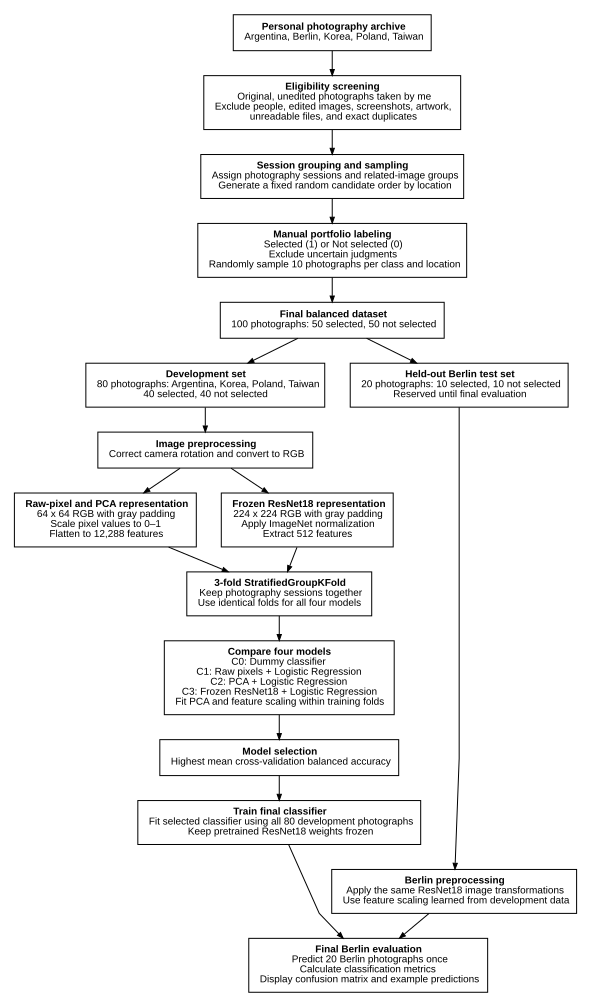

'photographic_eye_pipeline.svg'

In [2]:
#Machine learning pipeline diagram for learning my portfolio selection
# Installing Graphviz for creating the pipeline diagram
!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display

# Creating a black-and-white pipeline diagram
dot = Digraph("Photographic_Eye_Pipeline", format="svg")

dot.attr(rankdir="TB",
    bgcolor="white",
    nodesep="0.35",
    ranksep="0.35",
    splines="polyline",
    pad="0.2")

dot.attr("node",
    shape="box",
    style="solid",
    color="black",
    fontname="Arial",
    fontsize="10",
    margin="0.15,0.10",
    penwidth="1")

dot.attr("edge", color="black", arrowsize="0.6")

# Adding boxes with bold headings
def add_box(key, title, details):
    lines = "<BR/>".join(details)
    dot.node(key, f"<<B>{title}</B><BR/>{lines}>")

add_box("archive", "Personal photography archive", [
    "Argentina, Berlin, Korea, Poland, Taiwan"])

add_box("screen", "Eligibility screening", [
    "Original, unedited photographs taken by me",
    "Exclude people, edited images, screenshots, artwork,",
    "unreadable files, and exact duplicates"])

add_box("sessions", "Session grouping and sampling", [
    "Assign photography sessions and related-image groups",
    "Generate a fixed random candidate order by location"])

add_box("labels", "Manual portfolio labeling", [
    "Selected (1) or Not selected (0)",
    "Exclude uncertain judgments",
    "Randomly sample 10 photographs per class and location"])

add_box("dataset", "Final balanced dataset", [
    "100 photographs: 50 selected, 50 not selected"])

add_box("dev", "Development set", [
    "80 photographs: Argentina, Korea, Poland, Taiwan",
    "40 selected, 40 not selected"])

add_box("berlin", "Held-out Berlin test set", [
    "20 photographs: 10 selected, 10 not selected",
    "Reserved until final evaluation"])

add_box("pre", "Image preprocessing", [
    "Correct camera rotation and convert to RGB"])

add_box("pixels", "Raw-pixel and PCA representation", [
    "64 x 64 RGB with gray padding",
    "Scale pixel values to 0–1",
    "Flatten to 12,288 features"])

add_box("resnet", "Frozen ResNet18 representation", [
    "224 x 224 RGB with gray padding",
    "Apply ImageNet normalization",
    "Extract 512 features"])

add_box("cv", "3-fold StratifiedGroupKFold", [
    "Keep photography sessions together",
    "Use identical folds for all four models"])

add_box("models", "Compare four models", [
    "C0: Dummy classifier",
    "C1: Raw pixels + Logistic Regression",
    "C2: PCA + Logistic Regression",
    "C3: Frozen ResNet18 + Logistic Regression",
    "Fit PCA and feature scaling within training folds"])

add_box("select", "Model selection", [
    "Highest mean cross-validation balanced accuracy"])

add_box("retrain", "Train final classifier", [
    "Fit selected classifier using all 80 development photographs",
    "Keep pretrained ResNet18 weights frozen"])

add_box("testprep", "Berlin preprocessing", [
    "Apply the same ResNet18 image transformations",
    "Use feature scaling learned from development data"])

add_box("final", "Final Berlin evaluation", [
    "Predict 20 Berlin photographs once",
    "Calculate classification metrics",
    "Display confusion matrix and example predictions"])

# Connecting the dataset preparation steps
dot.edges([
    ("archive", "screen"),
    ("screen", "sessions"),
    ("sessions", "labels"),
    ("labels", "dataset")])

# Splitting development and Berlin data
with dot.subgraph() as s:
    s.attr(rank="same")
    s.node("dev")
    s.node("berlin")

dot.edge("dataset", "dev")
dot.edge("dataset", "berlin")

# Connecting the development branches
dot.edge("dev", "pre")
dot.edge("pre", "pixels")
dot.edge("pre", "resnet")

with dot.subgraph() as s:
    s.attr(rank="same")
    s.node("pixels")
    s.node("resnet")

dot.edge("pixels", "cv")
dot.edge("resnet", "cv")

dot.edges([
    ("cv", "models"),
    ("models", "select"),
    ("select", "retrain")])

# Keeping Berlin separate until final evaluation
dot.edge("berlin", "testprep", minlen="7")
dot.edge("retrain", "final")
dot.edge("testprep", "final")

# Displaying and saving the diagram
display(dot)
dot.render("photographic_eye_pipeline", cleanup=True)


**Machine Learning Pipeline Overview.** The diagram summarizes eligibility screening, session grouping, manual portfolio labeling, image preprocessing, and comparison of four models using three session-aware validation folds. Berlin remained separate from model development and selection and was used only for final evaluation. The diagram was created using Graphviz (Graphviz, n.d.).

## 2. Dataset and Experimental Design

### 2.1 Photograph Collection and Eligibility

I created my dataset from my personal photography archive, containing photographs from five locations: Argentina, Berlin, Korea, Poland, and Taiwan. I used my own photographs rather than an existing public dataset because I wanted to investigate my personal portfolio preferences.
<br> <br>
The archive that included only original, and unedited photos was manually screened. I excluded photographs containing people's faces anywhere in the frame for ethical purposes, including backgrounds, reflections, screens, or posters. I also excluded screenshots, edited images, photographs taken by others, and photographs dominated by paintings or other artwork.
<br> <br>
After screening, I checked for unreadable files and exact duplicates. I used **SHA-256** to create a content-based fingerprint for each file. Matching fingerprints helped identify exact duplicate copies, even when filenames differed (Python Software Foundation, n.d.). I also created stable photograph IDs to track images throughout the project without relying on filenames. However, this method does not detect visually similar photographs saved as different files, which required separate review. The complete inventory and file-validation procedure are documented in **Appendix A**.

### 2.2 Sampling, Photography Sessions, and Portfolio Labels

Before sampling, I organized photographs into photography sessions to reduce the risk of data leakage during cross-validation. Photographs taken during the same outing may share subjects, lighting, backgrounds, or compositions; if similar photographs appeared in both training and validation sets, model performance could be overly optimistic.
<br> <br>
I used **capture timestamps** to suggest session boundaries. A change of date or a gap of more than two hours suggested a new session. Then, I reviewed these assignments manually because time gaps do not always represent separate outings. Photographs without usable capture timestamps also required manual assignment. I identified closely related photographs within sessions so that similar images could remain together during validation (**Appendix B**).
<br> <br>
Next, I created a reproducible random sampling order within each location using a fixed seed of 156. I initially selected 35 eligible photographs per location for manual review but in case I was having sample size issues for selected/unselected categories, additional candidates could be drawn from the same random order when needed (**Appendix C**).
<br> <br>
I labeled each candidate based on whether I would include the original photograph in my portfolio, and then recorded uncertain judgments separately and excluded them from the final dataset. I then randomly selected 10 confidently selected and 10 confidently rejected photographs from each location using the same fixed seed (**Appendix D**).
<br> <br>
This produced a balanced dataset while preserving my original portfolio judgments. However, excluding uncertain photographs means the dataset primarily represents my clearer selection decisions, rather than the full range of photographs I might review.

### 2.3 Final Dataset and Evaluation Design

My final dataset contained 100 photographs: 50 selected and 50 non-selected. I reserved all 20 Berlin photographs as the final test set and used the remaining 80 photographs from Argentina, South Korea, Poland, and Taiwan for model development. Each development class contained 40 photographs, while Berlin contained 10 photographs per class.
<br> <br>
I held out Berlin to examine whether a model developed using four locations could predict my selections in a fifth. Berlin labels were used to construct the balanced test set, but neither Berlin photographs nor their labels were used for model training or model selection. For development, I used **StratifiedGroupKFold**, which combines two objectives: keeping photographs from the same session in one fold and attempting to preserve the class proportions across folds (Scikit-learn developers, n.d.-e). Group separation was really important because photographs from the same outing could be visually similar. Stratification was approximate because sessions could not be divided between folds.
<br> <br>
I compared three-fold and four-fold arrangements before training any models. Four folds produced one validation set containing only eight photographs, making its score highly sensitive to individual errors. Three folds gave more consistent validation sizes of 23–29 photographs, with both classes and all four development locations represented in each fold. Therefore, I selected three folds and used exactly the same training and validation partitions for all four models. The cross-validation results estimated performance on held-out photography sessions from locations represented during development. The separate Berlin test examined performance on one location excluded from development. Detailed checks of the session distributions and fold selection are documented in **Appendix E**.



### 2.4 Dataset Limitations and Potential Biases

My dataset contained only 100 photographs from five locations, and its labels reflected one person's subjective preferences. Since I deliberately selected equal numbers of both labels, the dataset does not represent how frequently I would select photographs from my full archive. Excluding uncertain judgments may also make prediction easier than evaluating all my photographs.
<br> <br>
Differences in subjects, composition, orientation, lighting, or color could be associated with my selection decisions. However, unequal photography-session sizes could also influence validation results. For example, one Taiwan session contributed 10 of the 23 photographs in a validation fold, giving that outing considerable influence on its score (**Appendix E**).
<br> <br>
To examine potential differences between the classes, I explored camera information, resolution, orientation, brightness, contrast, and saturation using only the development photographs (**Appendix F**). These analyses could identify associations worth investigating, but they could not establish which characteristics caused my portfolio decisions or the model's predictions.
<br> <br>
Finally, the Berlin test contained only 20 photographs, so a few individual errors could substantially change its performance metrics. Since Berlin was the only unseen location evaluated, its results cannot establish how well the model would generalize to other locations. Moreover, the balanced selection of Berlin photographs also means that its results describe this constructed test set rather than the natural distribution of my entire archive.

## 3. Setting Up the Dataset
After completing the manual screening, session grouping, and labeling procedures, I used the finalized metadata file for model development. This allowed me to reproduce the experiment without repeating the manual decisions documented in Appendices A–D.
<br> <br>
I first checked the dataset for incorrect labels, duplicate photograph IDs, and missing session assignments, then separated the development and Berlin test sets and created the cross-validation folds.

### 3.1 Loading the Final Dataset

I loaded the final metadata file from Google Drive using pandas. Here, each row represents one photograph and contains its unique ID, relative file path, location, portfolio label, and photography session.
<br> <br>
I used `"keep_default_na=False"` to preserve empty fields rather than automatically converting them into missing values, and also loaded portfolio labels as strings (`"0"` and `"1"`) so I could verify them before converting them into numerical values for training. I then checked that the file contained exactly 100 photographs with unique IDs, valid portfolio labels, and non-empty session assignments. These checks helped identify potential data errors before model training.

In [3]:
from pathlib import Path
import pandas as pd
from google.colab import drive

# Connecting Google Drive to access my photographs
drive.mount("/content/drive")

# Setting the path to my final dataset
project = Path("/content/drive/MyDrive/CS156_Photographic_Eye")
final_file = project / "03_final_dataset" / "final_photo_metadata.csv"

# Loading my final photograph information and labels
data = pd.read_csv(final_file,
    keep_default_na=False,
    dtype={"selected": str})

# Checking that the dataset contains 100 unique photographs
if len(data) != 100 or data["photo_id"].duplicated().any():
    raise ValueError("The final dataset must contain 100 unique photographs.")

# Checking that all photographs have valid labels
if not data["selected"].isin(["0", "1"]).all():
    raise ValueError("Some photographs have missing or incorrect labels.")

# Checking that every photograph has a session
if data["session_id"].eq("").any():
    raise ValueError("Some photographs are missing a session.")

Mounted at /content/drive


### 3.2 Preparing the Development and Test Sets

I separated the 80 development photographs from the 20 Berlin photographs reserved for final testing. Then, I verified the expected dataset sizes and checked that no photography session appeared in both sets. For development, I used `StratifiedGroupKFold` to create three validation folds. As explained in Section 2.3, this method keeps photographs from the same session together while attempting to preserve the proportions of both portfolio labels.
<br> <br>
Then, I set `"shuffle=True"` and `random_state=156` to make the fold assignment reproducible for the same dataset. Finally, I stored the resulting training and validation indices in folds and reused them for all four models. This ensured that differences in model performance were not caused by evaluating the models on different partitions. Additionally, the choice of three folds and the checks of their session and label distributions are documented in Appendix E.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

# Keeping Berlin separate for final testing
dev = data[data["location"] != "Berlin"].reset_index(drop=True)
test = data[data["location"] == "Berlin"].reset_index(drop=True)

# Checking the expected development and test sizes
if len(dev) != 80 or len(test) != 20:
    raise ValueError("The development or test set has an unexpected size.")

# Checking that no session appears in both sets
if set(dev["session_id"]) & set(test["session_id"]):
    raise ValueError("A photography session appears in both sets.")

# Creating three folds while keeping photographs from each session together
cv = StratifiedGroupKFold(n_splits=3,
    shuffle=True,
    random_state=156)

# Saving the same folds for comparing all models
folds = list(cv.split(dev,dev["selected"],groups=dev["session_id"]))

# Confirming the final split before training
print("Development photographs:", len(dev))
print("Berlin test photographs:", len(test))
print("Cross-validation folds:", len(folds))

Development photographs: 80
Berlin test photographs: 20
Cross-validation folds: 3


## 4. Image Preprocessing

My photographs have different dimensions and orientations, but the raw-pixel and PCA models require images with a consistent numerical representation. First, I used `"ImageOps.exif_transpose()"` to correct image orientation using the camera's stored metadata. Then, I converted each photograph to RGB and resized it to fit within 64 × 64 pixels using `ImageOps.pad()` with gray padding which preserved the original image proportions without cropping or stretching (Pillow, n.d.). I chose this approach because the entire composition may influence my portfolio decisions.
<br> <br>
Each RGB image contains three color channels (red, green, and blue), giving $64 \times 64 \times 3 = 12{,}288$ pixel values. I divided these values by 255 to scale them between 0 and 1, then flattened each image into a vector for logistic regression. PCA used the same vectors. Then, I chose 64 × 64 images to reduce the number of features and keep computation manageable with my small dataset. However, reducing the resolution may remove fine details, while gray padding introduces borders that could indirectly reveal the original image proportions.
<br> <br>
These transformations follow fixed rules and can be applied before cross-validation without learning from the validation photographs. Any preprocessing that learns from the data, such as PCA or feature standardization, must instead be fitted using only the training photographs within each fold.
<br> <br>
Finally, for ResNet18, I used 224 × 224 images and ImageNet normalization to follow the input conventions of its pretrained weights. I explain these steps and their differences from raw-pixel preprocessing in Section 5.4.

### 4.1 Loading the Image Tools

I used `Pillow` to open, rotate, resize, and process my photographs. Some photographs use the HEIC/HEIF format, which requires additional decoding support. I installed pillow-heif and registered its opener so these files could be processed using the same Pillow functions as other supported images (Pillow-Heif, n.d.).

In [5]:
# Installing support for opening HEIC photographs
!pip -q install pillow-heif

import numpy as np
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener

# Registering support for reading HEIC photographs
register_heif_opener()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 28.1 MB/s eta 0:00:00


### 4.2 Preparing the 64 × 64 Images

I applied the same preprocessing function to all 80 development photographs. Then flattened the resulting images into numerical feature vectors while preserving the order of their portfolio labels. Berlin photographs remained separate until the final evaluation.

In [6]:
# Creating a function for preparing photographs consistently
def prepare_photos(photos):

    images = []

    for file in photos["relative_path"]:

        path = project / file

        # Opening the photograph and correcting its rotation
        with Image.open(path) as img:
            picture = ImageOps.exif_transpose(img).convert("RGB")

            # Resizing with gray padding to preserve proportions
            picture = ImageOps.pad(
                picture,
                (64, 64),
                method=Image.Resampling.LANCZOS,
                color=(128, 128, 128))

            # Scaling pixel values between 0 and 1
            pixels = np.asarray(picture,dtype=np.float32) / 255.0

            images.append(pixels)

    return np.stack(images)


# Preparing the 80 development photographs
dev_images = prepare_photos(dev)

# Flattening each image into 12,288 pixel values
X_pixels = dev_images.reshape(len(dev_images), -1)

# Keeping labels in the same order as the photographs
y = dev["selected"].astype(int).to_numpy()

# Printing the number of photographs and pixel features
print("Pixel features:", X_pixels.shape)

Pixel features: (80, 12288)


### 4.3 Checking the Processed Photograph

I compared an original development photograph with its processed version to check how resizing affected its appearance. This helped verify that the preprocessing preserved the image proportions without cropping the composition.

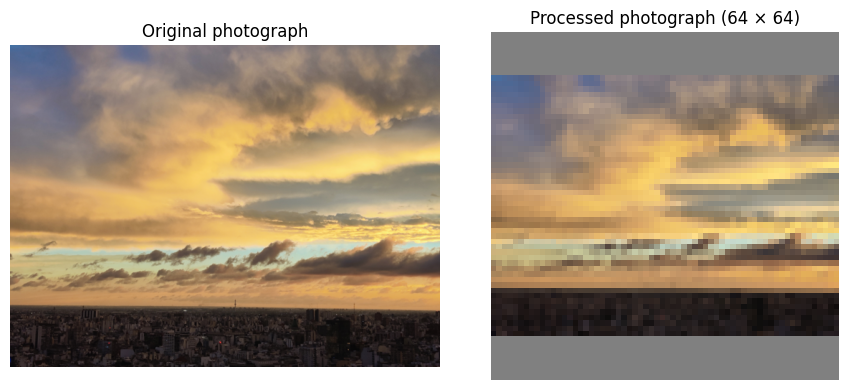

In [7]:
import matplotlib.pyplot as plt

# Opening one original development photograph
path = project / dev.loc[0, "relative_path"]

with Image.open(path) as img:

    # Correcting rotation and preparing the original for display
    original = ImageOps.exif_transpose(img).convert("RGB")
    original.thumbnail((600, 600))

# Comparing the original and processed photographs
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(original)
axes[0].set_title("Original photograph")

axes[1].imshow(dev_images[0])
axes[1].set_title("Processed photograph (64 × 64)")

# Hiding unnecessary plot markings
for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Preprocessing check:** The figure compares an original photograph with its 64 × 64 processed version. Gray padding, when needed, preserves the original proportions without cropping. However, resizing reduces visible detail. This illustrates the trade-off between preserving the composition and using fewer pixel features for model training.

## 5. Model Development and Cross-Validation

I compared four models to investigate whether visual information could predict my portfolio selections and whether different image representations affected prediction performance. The models were a dummy classifier, raw-pixel logistic regression, PCA followed by logistic regression, and pretrained ResNet18 features followed by logistic regression.
<br> <br>
All four models used the same three photography-session-aware validation folds. This allowed me to compare their performance on identical held-out photographs while reducing the risk of similar photographs appearing in training and validation.
<br> <br>
I used balanced accuracy as my primary evaluation metric because the validation folds did not necessarily contain equal numbers of selected and non-selected photographs. Balanced accuracy gives equal importance to identifying both classes correctly (Scikit-learn developers, n.d.-a).
<br> <br>
I also calculated accuracy, precision, recall, F1, and ROC-AUC to examine different aspects of performance, then selected the final model using only development results, keeping Berlin separate until the final evaluation.

### 5.1 Evaluating Models Using the Same Folds

I created one evaluation function to compare all four models consistently. For each validation fold, the function used `clone()` to create a fresh, unfitted copy of the model. It then trained that copy on the training photographs and evaluated its predictions on the held-out photography sessions.
<br> <br>
The function calculated balanced accuracy, accuracy, precision, recall, F1, and ROC-AUC. Precision, recall, and F1 treated Selected (1) as the positive class. ROC-AUC measured how well predicted probabilities ranked selected photographs above non-selected photographs across possible classification thresholds.
<br> <br>
Any preprocessing that learned from the data, such as PCA or feature standardization, was fitted only on the training photographs within each fold. The fitted transformations were then applied to the validation photographs which prevented validation information from influencing model fitting (Scikit-learn developers, n.d.-b).

In [8]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score)

# Creating one function for evaluating all models
def evaluate_model(name, model, features):

    scores = []

    # Evaluating the model using the same three folds
    for number, (train_idx, val_idx) in enumerate(folds, start=1):

        # Training a new model using only training photographs
        current_model = clone(model)
        current_model.fit(features[train_idx], y[train_idx])

        # Predicting labels and probabilities for validation photographs
        predicted = current_model.predict(features[val_idx])
        probabilities = current_model.predict_proba(
            features[val_idx])[:, 1]

        # Calculating the validation scores
        scores.append({"model": name,
            "fold": number,
            "balanced_accuracy": balanced_accuracy_score(
                y[val_idx], predicted),
            "accuracy": accuracy_score(
                y[val_idx], predicted),
            "precision": precision_score(
                y[val_idx], predicted, zero_division=0),
            "recall": recall_score(
                y[val_idx], predicted, zero_division=0),
            "f1": f1_score(
                y[val_idx], predicted, zero_division=0),
            "roc_auc": roc_auc_score(
                y[val_idx], probabilities)})

    return pd.DataFrame(scores)

### 5.2 Dummy Classifier and Raw-Pixel Logistic Regression

**C0: Dummy Classifier**

I used a dummy classifier as a baseline to determine whether the models using visual information performed better than a simple prediction rule. The most_frequent strategy always predicts whichever portfolio label is most common in its training fold, without examining the photographs.
<br> <br>
When both classes are present in the validation set, always predicting one class produces balanced accuracy of 0.50. Therefore, a model achieving a higher score provides evidence that its predictions are more useful than this baseline on the evaluated photographs.
<br> <br>
**C1: Raw-Pixel Logistic Regression**

Logistic regression provided a simple starting point for image classification. It used the 12,288 pixel values from each photograph to estimate the probability that I would select it for my portfolio. The model combined these features using learned weights and applied a sigmoid function:

$$
P(y=1\mid\mathbf{x})=\frac{1}{1+e^{-(\mathbf{w}^{T}\mathbf{x}+b)}}
$$

Here, $\mathbf{x}$ represents the pixel values, $\mathbf{w}$ contains their learned weights, and $b$ is the intercept. The sigmoid function converts the weighted sum into a probability between 0 and 1. However, the number of pixel features was much larger than the number of training photographs, creating a risk of overfitting. Therefore, I used L2 regularization, which adds a penalty for large model weights to the logistic regression loss function. This discourages the model from relying on excessively large coefficients that may fit the training data without generalizing well.
<br> <br>
I fixed the regularization parameter at $C=1.0$, where $C$ is the inverse of regularization strength. A smaller $C$ applies stronger regularization, while a larger $C$ applies weaker regularization. I used `solver="liblinear"` to optimize the binary logistic regression model and `max_iter=2000` to allow sufficient optimization iterations. I kept these settings fixed rather than tuning them using validation or Berlin results (Scikit-learn developers, n.d.-c).
<br> <br>
One limitation is that logistic regression treats pixel positions as separate input features rather than explicitly learning spatial patterns. A similar subject appearing in a different position may therefore produce substantially different pixel inputs, making this representation less suitable for recognizing visual similarities across photographs.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Creating the dummy model as a baseline
dummy = DummyClassifier(strategy="most_frequent")

# Creating logistic regression with fixed settings
pixel_model = LogisticRegression(
    C=1.0,
    penalty="l2",
    max_iter=2000,
    solver="liblinear",
    random_state=156)

# Evaluating both models using the same three folds
model_scores = pd.concat([
    evaluate_model("Dummy", dummy, X_pixels),
    evaluate_model("Raw pixels + LR", pixel_model, X_pixels)], ignore_index=True)


### 5.3 PCA + Logistic Regression

**C2: PCA + Logistic Regression**

Principal Component Analysis (PCA) reduces the number of input features by identifying new directions that capture variation across photographs. These directions, called principal components, summarize patterns in the original pixel values. Therefore, instead of keeping all 12,288 pixel features, I used PCA to retain the smallest number of components explaining at least 95% of the variation in each training fold:

$$
\frac{\sum_{j=1}^{k}\lambda_j}{\sum_{j=1}^{m}\lambda_j}\geq 0.95
$$

Here, $\lambda_j$ is the variance explained by component $j$, $k$ is the number of retained components, and $m$ is the total number of available components. The components are ordered from highest to lowest explained variance.
<br> <br>
PCA identifies directions that capture the greatest variation in the training photographs. If $S_{\mathrm{train}}$ is the covariance matrix of the centered training pixel features, the first principal component is the direction that maximizes this variance:

$$
\mathbf{v}_1 = \underset{\|\mathbf{v}\|_2=1}{\arg\max}\; \mathbf{v}^{T}S_{\mathrm{train}}\mathbf{v}
$$

Here, $\mathbf{v}$ is a direction in the pixel feature space, and $\mathbf{v}^{T}S_{\mathrm{train}}\mathbf{v}$ measures the variance along that direction. The constraint $\|\mathbf{v}\|_2=1$ prevents the variance from increasing simply by making the vector longer. Later components capture additional variance while remaining orthogonal to earlier components. Scikit-learn calculates these directions using singular value decomposition (SVD), without explicitly constructing the covariance matrix.
<br> <br>
Importantly, this objective maximizes variation in the photographs, not the ability to predict my portfolio labels. Therefore, retaining 95% of image variance does not guarantee retaining the visual information most useful for classification. This helps explain why PCA could preserve most pixel variation yet perform worse than ResNet18 in my experiment.
<br> <br>
I selected the 95% threshold to reduce the number of features while preserving most of the variation in the photographs. Scikit-learn's PCA implementation supports this selection rule through `n_components=0.95` (Scikit-learn developers, n.d.-d).
<br> <br>
I used Scikit-learn's Pipeline to combine PCA and logistic regression. My pipeline applies the preprocessing and classification steps together, allowing PCA to be fitted separately within each training fold before transforming its validation photographs. This prevents information from the validation data from influencing the principal components (Scikit-learn developers, n.d.-b). Moreover, I used the same logistic regression settings and validation folds as the raw-pixel model. This comparison tested whether reducing pixel dimensionality improved prediction performance for my dataset.

In [10]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Combining PCA and logistic regression in one model
pca_model = Pipeline([
    ("pca", PCA(n_components=0.95,svd_solver="full")),
    ("logistic", pixel_model)])

# Evaluating PCA using the same three folds
pca_scores = evaluate_model("PCA + LR",pca_model,X_pixels)

### 5.4 Frozen ResNet18 Features + Logistic Regression

**C3: Pretrained ResNet18 + Logistic Regression**

For the fourth model, I used ResNet18, a convolutional neural network (CNN) pretrained on ImageNet. Since my development dataset contained only 80 photographs, training an entire CNN from scratch would require learning many parameters from very few examples. I chose ResNet18 because it is relatively compact compared with larger CNN architectures and has already learned useful visual patterns from a much larger image dataset.
<br> <br>
Unlike raw-pixel logistic regression, a CNN uses learned filters to examine neighboring pixels and identify local visual patterns. Early layers can detect simple features such as edges and textures, while deeper layers combine these into more complex representations. Additionally, ResNet18 uses residual connections, which allow information to bypass certain layers. A simplified residual connection can be represented as:

$$
\mathbf{h}_{\mathrm{out}} =
F(\mathbf{h}_{\mathrm{in}})+\mathbf{h}_{\mathrm{in}}
\
$$

Here, $\mathbf{h}_{\mathrm{in}}$ is the input to a residual block, and $F$ represents transformations learned by its layers. The block adds the original input to those transformations before its final activation. This helps information and gradients pass through deeper networks during training. The equation describes an identity shortcut; some ResNet blocks also transform the shortcut when dimensions change (He et al., 2016).
<br> <br>
The benefit of a residual connection can also be explained using derivatives. For a simplified identity-shortcut block before its final activation, let $\mathbf{z}=F(\mathbf{h})+\mathbf{h}$. Differentiating the output with respect to its input gives:

$$
\frac{\partial \mathbf{z}}{\partial \mathbf{h}}=J_F(\mathbf{h})+I
$$

Here, $J_F(\mathbf{h})$ is the Jacobian matrix of the learned transformation $F$, which describes how its outputs change with its inputs. $I$ is the identity matrix contributed by the shortcut connection. The derivative therefore contains a direct path for gradients, alongside the path through the learned layers. This can make deeper networks easier to optimize, although it does not guarantee that gradients will never vanish. Actual ResNet blocks also include activation functions and sometimes projection shortcuts, so this equation illustrates the simplified case.
<br> <br>
In my experiment, I did not train ResNet18 or update its pretrained weights. This mathematical explanation describes why residual connections are useful when training the original network, whose learned features I reused for my portfolio classifier.
<br> <br>
Rather than using ResNet18 to predict its original ImageNet classes, I replaced its final classification layer with `torch.nn.Identity()`. This allowed me to extract a 512-dimensional feature vector from each photograph. These features summarize visual information learned during ImageNet training. I then used them as inputs to logistic regression, which learned to predict my portfolio labels.
<br> <br>
I kept all ResNet18 weights frozen using `requires_grad_(False)` and switched the network into evaluation mode using `eval()`. Therefore, only the logistic regression classifier learned from my portfolio labels. This approach, called fixed feature extraction, is a form of transfer learning: it reuses knowledge from a previously trained model for a different prediction task (Chilamkurthy, 2025; PyTorch, n.d.).
<br> <br>
For image preprocessing, I corrected orientation, converted photographs to RGB, and resized them to 224 × 224 pixels using gray padding. I chose padding rather than cropping because preserving the entire composition may be important for my selection decisions. Then, I converted pixel values into tensors and applied the fixed color normalization associated with the pretrained ImageNet weights (PyTorch, n.d.).
<br> <br>
This preprocessing differs from the raw-pixel models, which use 64 × 64 images scaled between 0 and 1. It also differs from the pretrained model's usual center-crop procedure because I wanted to preserve the whole photograph.


### Loading the Pretrained ResNet18

In [11]:
import torch
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

# Loading ResNet18 with pretrained ImageNet weights
weights = ResNet18_Weights.IMAGENET1K_V1
cnn = resnet18(weights=weights)

# Removing the final prediction layer to extract image features
cnn.fc = torch.nn.Identity()

# Keeping the pretrained weights unchanged
cnn.requires_grad_(False)
cnn.eval()

# Using a GPU when available
device = "cuda" if torch.cuda.is_available() else "cpu"
cnn = cnn.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 98.7MB/s]


### Extracting Image Features

I passed the 80 development photographs through the frozen ResNet18 network in batches of eight to reduce memory use. I used `torch.inference_mode()` because I only needed the pretrained network's outputs, not gradients for updating its weights.
Then, I extracted the resulting 512 features for each photograph, preserving the original photograph order. Since ResNet18's weights and evaluation settings remained fixed, this feature extraction did not learn from the validation labels or adapt to their photographs. Moreover, the feature scaler and logistic regression were still fitted separately within each training fold.

In [12]:
# Applying the color normalization used during ImageNet training
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225])])

# Creating a list for saving image features
features = []

# Processing photographs in groups of eight to save memory
for start in range(0, len(dev), 8):

    batch_images = []

    for file in dev["relative_path"].iloc[start:start + 8]:

        path = project / file

        # Opening the photograph and correcting its rotation
        with Image.open(path) as img:
            picture = ImageOps.exif_transpose(img).convert("RGB")

            # Resizing with gray padding to preserve proportions
            picture = ImageOps.pad(picture,(224, 224),
                method=Image.Resampling.LANCZOS,
                color=(128, 128, 128))

            # Preparing the photograph for ResNet18
            batch_images.append(transform(picture))

    # Combining the photographs into one group
    batch = torch.stack(batch_images).to(device)

    # Extracting features without training the CNN
    with torch.inference_mode():
        output = cnn(batch)

    # Saving the extracted features
    features.append(output.cpu().numpy())

# Combining features in the original photograph order
X_cnn = np.concatenate(features, axis=0)

# Printing the number of photographs and features
print("CNN features:", X_cnn.shape)

CNN features: (80, 512)


### Evaluating ResNet18

Before training logistic regression, I used **StandardScaler** to standardize the 512 extracted features. This was different from ImageNet normalization: ImageNet normalization used fixed values to prepare RGB pixels for ResNet18, while StandardScaler learned the mean and standard deviation of each extracted feature from my training data.
<br> <br>
For a feature with nonzero standard deviation, standardization can be represented as:

$$
z_j=\frac{h_j-\mu_{j,\mathrm{train}}}{\sigma_{j,\mathrm{train}}}
$$

Here, $h_j$ is the original value of feature $j$, while $\mu_{j,\mathrm{train}}$ and $\sigma_{j,\mathrm{train}}$ are its mean and standard deviation in the training fold. This puts features on more comparable numerical scales, reducing the possibility that differences in feature magnitude disproportionately affect regularized logistic regression.
<br> <br>
I combined StandardScaler and logistic regression using a Pipeline. The pipeline fitted both steps using only the training photographs within each fold and applied the learned scaling to validation photographs. This prevented validation data from influencing the feature standardization (Scikit-learn developers, n.d.-b).
<br> <br>
I evaluated the model using the same three photography-session folds and logistic regression settings as the earlier models. This tested whether pretrained visual features could better predict my selections than raw pixels or PCA-reduced pixels. However, the comparison did not isolate the effect of the pretrained architecture. The models also differed in image resolution, preprocessing, and feature representation. Therefore, better ResNet18 performance would support the usefulness of this complete approach, but would not establish that ResNet18 specifically recognized my photographic composition preferences.

In [13]:
from sklearn.preprocessing import StandardScaler

# Combining feature scaling with logistic regression
cnn_model = Pipeline([("scale", StandardScaler()),("logistic", pixel_model)])

# Evaluating CNN features using the same three folds
cnn_scores = evaluate_model("ResNet18 + LR",cnn_model,X_cnn)

### 5.5 Comparing All Four Models

I compared the four models using their **mean balanced accuracy** across the three validation folds. Balanced accuracy is the average recall of the two classes. It measures how well the model identifies both selected and non-selected photographs, even when the validation sets have different class proportions (Scikit-learn developers, n.d.-a).
<br> <br>
For binary classification, balanced accuracy can be calculated as:

$$
\text{Balanced Accuracy}=\frac{1}{2}\left(\frac{TN}{TN+FP}+\frac{TP}{TP+FN}\right)
$$

Here, $TN$ and $TP$ are correctly predicted non-selected and selected photographs. $FP$ represents non-selected photographs incorrectly predicted as selected, while $FN$ represents selected photographs incorrectly predicted as non-selected. The first fraction is recall for label 0, and the second is recall for label 1.
<br> <br>
I selected the model with the highest mean balanced accuracy for final evaluation on Berlin. Each validation fold contributed equally to the mean, even though the folds contained different numbers of photographs.
I also calculated the standard deviation of balanced accuracy to examine how much model performance varied across folds. Accuracy, precision, recall, F1, and ROC-AUC provided additional information, but they did not determine which model was selected.
<br> <br>
Since I compared four models using a small dataset, the highest cross-validation score could be optimistic. I therefore reserved Berlin for an independent evaluation and did not change the selected model's settings based on its Berlin performance.



### Comparing and Selecting Models

In [14]:
# Combining the validation results from all four models
all_scores = pd.concat(
    [model_scores, pca_scores, cnn_scores],
    ignore_index=True)

# Checking that all four models have three different fold results
counts = all_scores.groupby("model")["fold"].nunique()

if (
    len(counts) != 4
    or not counts.eq(3).all()
    or all_scores[["model", "fold"]].duplicated().any()
):
    raise ValueError("Expected three results for each of four models.")

# Calculating average scores and variation across folds
comparison = (
    all_scores.groupby("model", sort=False)
    .agg(
        BA_mean=("balanced_accuracy", "mean"),
        BA_SD=("balanced_accuracy", "std"),
        Accuracy=("accuracy", "mean"),
        Precision=("precision", "mean"),
        Recall=("recall", "mean"),
        F1=("f1", "mean"),
        ROC_AUC=("roc_auc", "mean"))
    .sort_values("BA_mean", ascending=False))

# Displaying the final four-model comparison
display(comparison.round(3))

# Selecting the model with the highest mean balanced accuracy
best_name = comparison["BA_mean"].idxmax()

# Printing the selected model before testing Berlin
print("Selected model:", best_name)

,BA_mean,BA_SD,Accuracy,Precision,Recall,F1,ROC_AUC
model,,,,,,,
ResNet18 + LR,0.654,0.118,0.645,0.631,0.684,0.647,0.655
PCA + LR,0.542,0.056,0.549,0.541,0.511,0.525,0.517
Raw pixels + LR,0.526,0.136,0.532,0.531,0.457,0.491,0.514
Dummy,0.500,0.000,0.461,0.145,0.333,0.202,0.500


Selected model: ResNet18 + LR


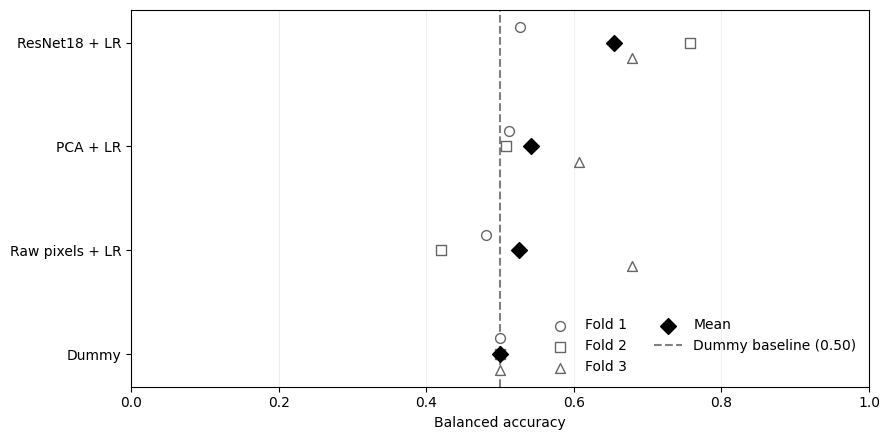

In [15]:
# Keeping models in order of average balanced accuracy
names = comparison.index.tolist()
positions = np.arange(len(names))

# Creating the model comparison figure
fig, ax = plt.subplots(figsize=(9, 4.5))

# Showing the three validation scores for each model
for fold, marker, shift in [
    (1, "o", -0.15),
    (2, "s", 0),
    (3, "^", 0.15)
]:
    scores = (all_scores[all_scores["fold"] == fold]
        .set_index("model")
        .loc[names, "balanced_accuracy"])

    ax.scatter(
        scores,
        positions + shift,
        marker=marker,
        s=50,
        facecolors="white",
        edgecolors="0.4",
        label=f"Fold {fold}",
        zorder=3
)

# Marking the average balanced accuracy for each model
ax.scatter(comparison["BA_mean"],
    positions,
    marker="D",
    s=65,
    color="black",
    label="Mean",
    zorder=4)

# Marking the dummy classifier baseline
ax.axvline(0.5, color="gray", linestyle="--", label="Dummy baseline (0.50)")

# Labeling the models and accuracy scale
ax.set_yticks(positions)
ax.set_yticklabels(names)
ax.set_xlabel("Balanced accuracy")
ax.set_xlim(0, 1)
ax.invert_yaxis()

# Adding light grid lines for comparing scores
ax.grid(axis="x", alpha=0.2)

# Showing the marker labels
ax.legend(loc="lower right", frameon=False, ncol=2)

plt.tight_layout()
plt.show()

**Figure 1. Balanced accuracy across three photography-session validation folds.** Black diamonds show the mean balanced accuracy for each model, while circles, squares, and triangles show individual fold scores. The dashed line marks the dummy baseline of 0.50. ResNet18 achieved the highest mean balanced accuracy (0.654), but its performance varied across folds (0.526–0.758). The slight vertical separation of fold markers is only for readability.

### Interpreting the Model Comparison

ResNet18 with logistic regression achieved the highest mean balanced accuracy of 0.654, followed by PCA with logistic regression (0.542), raw-pixel logistic regression (0.526), and the dummy classifier (0.500).
<br> <br>
ResNet18 performed 15.4 percentage points above the dummy baseline and 11.2 percentage points above PCA. These findings were consistent with H1 and H2 for this dataset which mentioned that all three models using image information exceeded the dummy baseline, and the pretrained ResNet18 approach achieved the highest development score.
<br> <br>
However, ResNet18's balanced accuracy ranged from 0.526 to 0.758 across the three validation folds, with a standard deviation of approximately 0.118. This variation suggests that its performance depended on which photography sessions were held out. The small validation sets and unequal session sizes make it difficult to determine the exact causes.
Moreover, the differences between the models also require cautious interpretation. PCA only slightly exceeded raw-pixel logistic regression, and the ResNet18 comparison combined several changes, including higher image resolution, different preprocessing, and pretrained visual features. Therefore, the results do not establish which individual difference caused ResNet18's better performance.
<br> <br>
Furthermore, selecting the highest-scoring model from four candidates may produce an optimistic development estimate. Plus, three validation folds provide limited evidence about how consistently ResNet18 would outperform the alternatives on other photographs.
Following my predefined selection rule, I selected ResNet18 with logistic regression for the final Berlin evaluation. I kept its settings unchanged and retrained the classifier using all 80 development photographs.
<br> <br>
Overall, these results provide preliminary evidence that pretrained visual features may help predict my portfolio decisions. The Berlin test provides a separate evaluation of this selected approach on photographs from a location excluded from model development.

## 6. Final Evaluation on Berlin Photographs

After comparing the four models, I selected ResNet18 with logistic regression because it achieved the highest mean balanced accuracy during cross-validation (0.654).
<br> <br>
I trained a fresh version of the selected classifier using all 80 development photographs. During cross-validation, each classifier was trained on only a subset of these photographs. Training the final classifier on all 80 allowed it to learn from more labeled examples before evaluating Berlin.
The pretrained ResNet18 weights remained unchanged. The feature scaler learned from the 512 extracted features of the development photographs, while logistic regression learned to predict my portfolio labels. Neither component was fitted using Berlin photographs or their labels.
<br> <br>
I then processed the 20 Berlin photographs using the same image transformations and frozen ResNet18 feature extractor. Berlin photographs had not been used during model development or selection, although their labels had been used earlier to construct the balanced test set. I evaluated the final model without changing its settings based on Berlin results.
Finally, I calculated balanced accuracy, accuracy, precision, recall, F1, and ROC-AUC. I also examined a confusion matrix and individual predictions to understand the model's errors. Ultimately, I compared Berlin performance with the development cross-validation mean to evaluate H3 while considering the limitations of the small test set.


### 6.1 Training the Selected Model
I first verified that ResNet18 with logistic regression was the model selected during development. I then used `clone(cnn_model)` to create a fresh copy of the classification pipeline and fitted it using all 80 development photographs.
This fitted a new StandardScaler and logistic regression classifier using the extracted ResNet18 features and their portfolio labels. ResNet18 itself was not retrained because its pretrained weights remained frozen.

In [16]:
# Checking that ResNet18 was selected during development
if best_name != "ResNet18 + LR":
    raise ValueError("The selected model is not ResNet18.")

# Training a fresh copy using all 80 development photographs
final_model = clone(cnn_model).fit(X_cnn, y)

### 6.2 Preparing the Berlin Photographs

I applied the same ResNet18 preprocessing steps used during development. I then corrected image orientation, converted each photograph to RGB, resized it to 224 × 224 pixels with gray padding, and applied the same fixed ImageNet normalization.
Berlin photographs were passed the  through the frozen ResNet18 network in batches of eight to extract 512 features per photograph. I used `torch.inference_mode()` because no CNN weights needed to be updated.
<br> <br>
I checked that the resulting feature matrix contained 20 rows and 512 columns, matching the expected number of Berlin photographs and extracted features. These features were then passed to the final classifier, which used the scaler already fitted on the development photographs. No preprocessing parameters were learned from Berlin.

In [17]:
# Creating a list for saving Berlin image features
test_features = []

# Processing Berlin photographs using the same ResNet18 steps
for start in range(0, len(test), 8):

    batch_images = []

    for file in test["relative_path"].iloc[start:start + 8]:

        path = project / file

        # Opening the photograph and correcting its rotation
        with Image.open(path) as img:
            picture = ImageOps.exif_transpose(img).convert("RGB")

            # Resizing with the same gray padding
            picture = ImageOps.pad(
                picture,
                (224, 224),
                method=Image.Resampling.LANCZOS,
                color=(128, 128, 128))

            # Applying the same image normalization
            batch_images.append(transform(picture))

    # Combining the photographs into one group
    batch = torch.stack(batch_images).to(device)

    # Extracting features without training ResNet18
    with torch.inference_mode():
        output = cnn(batch)

    # Saving the extracted Berlin features
    test_features.append(output.cpu().numpy())

# Combining the Berlin features in their original order
X_test_cnn = np.concatenate(test_features, axis=0)

# Checking the expected number of photographs and features
if X_test_cnn.shape != (20, 512):
    raise ValueError("The Berlin features have an unexpected shape.")

print("Berlin features:", X_test_cnn.shape)

Berlin features: (20, 512)


### 6.3 Evaluating the Final Model

I used the final classifier to predict whether each Berlin photograph would be selected for my portfolio. I also calculated the predicted probability of label 1 (Selected) for each photograph.
<br> <br>
Then, I evaluated these predictions using balanced accuracy as the primary metric, consistent with the model-selection procedure. I also calculated accuracy, precision, recall, F1, and ROC-AUC. ROC-AUC used the predicted probabilities, while the other metrics used the predicted class labels.
<br> <br>
Finally, I calculated the difference between Berlin balanced accuracy and the selected model's mean development cross-validation balanced accuracy. This provided a descriptive comparison of the two evaluation results, rather than a statistical test of whether the model generalizes across locations.

In [18]:
# Keeping Berlin labels in the same order as the features
y_test = test["selected"].astype(int).to_numpy()

# Predicting portfolio labels and probabilities for Berlin
predicted = final_model.predict(X_test_cnn)
probabilities = final_model.predict_proba(X_test_cnn)[:, 1]

# Calculating the final Berlin performance scores
test_result = pd.DataFrame([{
    "Balanced accuracy": balanced_accuracy_score(y_test, predicted),
    "Accuracy": accuracy_score(y_test, predicted),
    "Precision": precision_score(y_test, predicted, zero_division=0),
    "Recall": recall_score(y_test, predicted, zero_division=0),
    "F1": f1_score(y_test, predicted, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, probabilities)}])

# Displaying the final Berlin results
display(test_result.round(3))

# Comparing Berlin balanced accuracy with the development average
gap = (test_result.loc[0, "Balanced accuracy"]- comparison.loc[best_name, "BA_mean"])

print("Berlin minus development balanced accuracy:", round(gap, 3))

,Balanced accuracy,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.6,0.6,0.6,0.6,0.6,0.62


Berlin minus development balanced accuracy: -0.054


### Interpreting the Berlin Results

The final model achieved a balanced accuracy of 0.600 on Berlin, compared with a mean cross-validation balanced accuracy of 0.654. This is a decrease of 5.4 percentage points.
However, this difference does not necessarily mean that the model performs worse because Berlin is a new location. The final classifier was trained using all 80 development photographs, while each cross-validation classifier used only its training folds. The evaluation sets also contain different photographs and photography sessions.
<br> <br>
Moreover, the Berlin test contains only 20 photographs, with 10 from each class. Correcting one incorrect prediction, with all other predictions unchanged, increases balanced accuracy by five percentage points. Therefore, this small test set does not provide enough evidence to determine whether the difference reflects a consistent decline in performance on unseen locations.
<br> <br>
The Berlin balanced accuracy of 0.600 is above the 0.50 baseline, as expected in H3. This result is consistent with my hypothesis, but it does not demonstrate that the model will consistently outperform the baseline across other unseen locations.

### 6.4 Examining Classification Errors

This shows how many photographs were correctly or incorrectly classified in each portfolio category.

A false positive occurs when the model predicts Selected (1) for a photograph I labeled Not selected (0). A false negative occurs when the model predicts Not selected (0) for a photograph I labeled Selected (1). Both types of error matter because the model should identify photographs I prefer while also recognizing those I would reject.

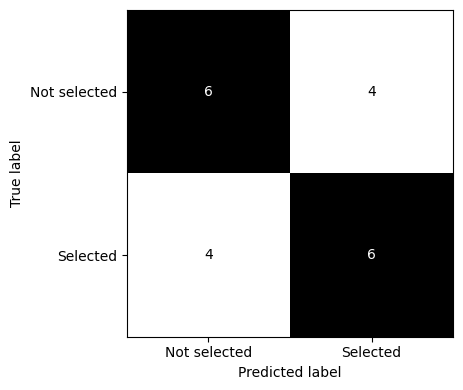

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Counting correct and incorrect Berlin predictions
cm = confusion_matrix(y_test, predicted, labels=[0, 1])

# Creating the confusion matrix figure
fig, ax = plt.subplots(figsize=(5, 4))

# Displaying the two actual and predicted labels
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not selected", "Selected"]).plot(ax=ax, cmap="Grays",
    colorbar=False)

plt.tight_layout()
plt.show()

**Figure 2. Confusion matrix for the final ResNet18 model on 20 Berlin photographs.** The model correctly classified 12 photographs and incorrectly classified 8. It correctly identified 6 selected photographs and 6 non-selected photographs. The errors consisted of 4 false positives and 4 false negatives. Because the test set contained equal numbers of both classes, accuracy and balanced accuracy were both 0.600.

### 6.5 Examining Individual Berlin Predictions

The confusion matrix showed how many predictions were correct or incorrect, but it did not identify which photographs the model struggled with.
To examine individual predictions, I displayed one Berlin photograph from each of the four outcomes: correct rejection, false positive, false negative, and correct selection. I randomly selected one photograph within each outcome using a fixed seed of 156, rather than manually choosing examples that supported a preferred explanation.
<br> <br>
I used these examples to examine possible differences in composition, lighting, color, and subject matter. However, four photographs cannot establish which visual features caused the model's predictions. The images provide qualitative examples of correct and incorrect classifications, not a formal explanation of the model's internal decisions.
<br> <br>
I also kept the model unchanged after examining these photographs because Berlin was reserved for final evaluation.

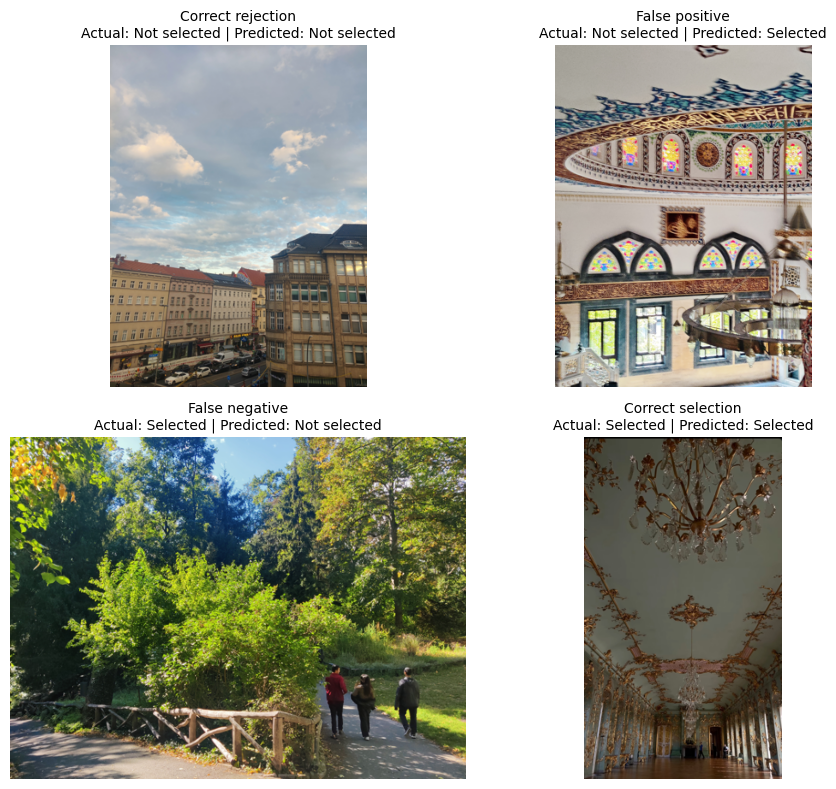

In [20]:
# Matching Berlin photographs with their actual and predicted labels
photo_results = test[["relative_path"]].reset_index(drop=True).copy()
photo_results["actual"] = y_test
photo_results["predicted"] = predicted

# Defining the four prediction outcomes
groups = [
    ("Correct rejection", 0, 0),
    ("False positive", 0, 1),
    ("False negative", 1, 0),
    ("Correct selection", 1, 1)]

# Creating a figure with four Berlin photographs
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Selecting one random photograph from each outcome
for ax, (name, actual, guess) in zip(axes.flat, groups):

    photos = photo_results[(photo_results["actual"] == actual)
        & (photo_results["predicted"] == guess)]

    photo = photos.sample(n=1, random_state=156).iloc[0]

    # Opening the photograph and correcting its rotation
    with Image.open(project / photo["relative_path"]) as img:
        picture = ImageOps.exif_transpose(img).convert("RGB")
        picture.thumbnail((500, 400))

    # Displaying the photograph
    ax.imshow(picture)

    # Showing the actual and predicted labels
    true_label = "Selected" if actual == 1 else "Not selected"
    pred_label = "Selected" if guess == 1 else "Not selected"

    ax.set_title(f"{name}\nActual: {true_label} | Predicted: {pred_label}",
        fontsize=10)

    # Hiding unnecessary plot markings
    ax.axis("off")

plt.tight_layout()
plt.show()

**Figure 3. Examples of correct and incorrect Berlin predictions.** One photograph was randomly selected from each confusion-matrix outcome using a fixed seed of 156. These examples allow a qualitative examination of the model's predictions, but they do not establish which visual characteristics influenced its decisions.

## 7. Discussion, Limitations, and Future Improvements

### 7.1 What Did I Learn?

Overall, my results were consistent with all three hypotheses, although the evidence remains preliminary.
<br> <br>
For **H1**, all three models using visual information achieved higher mean balanced accuracy than the dummy classifier (0.500). For **H2**, ResNet18 with logistic regression achieved the highest mean balanced accuracy (0.654), outperforming raw-pixel logistic regression (0.526) and PCA with logistic regression (0.542). Its 15.4-percentage-point advantage over the dummy baseline suggests that pretrained visual features may contain information useful for predicting my portfolio selections.
However, the differences between models were estimated using only three validation folds. The ResNet18 approach also used higher-resolution images and different preprocessing, so its advantage cannot be attributed solely to the pretrained CNN features.
<br> <br>
For **H3**, the selected model correctly classified 12 of 20 Berlin photographs, achieving a balanced accuracy of 0.600. This exceeded the 0.50 baseline on photographs from a location excluded from model development. However, eight photographs were incorrectly classified, and the small test set does not establish that the model would consistently outperform the baseline on other unseen locations.
<br> <br>
Together, these results suggest that my portfolio decisions may contain visual patterns that machine learning can partially identify. However, they do not establish that the model has learned a reliable or generalizable representation of my photographic preferences.
<br> <br>
### 7.2 Why Might Prediction Be Difficult?
One possible explanation is that my portfolio decisions depend on combinations of composition, lighting, colors, and subjects. Raw-pixel logistic regression does not explicitly learn spatial patterns, making it sensitive to where objects appear in photographs. PCA preserves directions of high image variation without considering my portfolio labels, so it may discard information relevant to my selections. ResNet18 provides more complex visual representations, but its pretrained weights were learned for ImageNet classification rather than my personal preferences.
<br> <br>
The Berlin confusion matrix provides another indication of the model's limitations. It produced four false positives, predicting that I would select photographs I had rejected, and four false negatives, missing photographs I had selected. This means the model made mistakes in both directions rather than consistently favoring one portfolio label. Although the examples in Figure 3 help illustrate these errors, they cannot establish whether particular subjects, lighting conditions, or compositions caused the incorrect predictions.
<br> <br>
The small dataset also limits what I can conclude. Development included only 80 photographs, and ResNet18's balanced accuracy varied from 0.526 to 0.758 across the three validation folds. Different photography sessions and unequal session sizes may contribute to this variation. Furthermore, selecting the best-performing approach from four models may produce an optimistic development estimate.
<br> <br>
Another possibility is that the models learned incidental differences between photographs rather than stable aspects of my preferences. Appendix F found that associations between selection labels and simple visual characteristics, such as saturation, differed across locations. However, these exploratory findings do not demonstrate which characteristics influenced the models' predictions.
<br> <br>
Finally, I deliberately balanced the portfolio labels and excluded uncertain judgments. Consequently, the dataset represents my clearer selection decisions rather than the full range of photographs I usually review. Evaluating only 20 photographs from one unseen location also limits conclusions about generalization. These limitations mean that the observed scores should be treated as preliminary evidence rather than reliable estimates of future performance.
<br> <br>
### 7.3 How Could I Improve This Project?

My first priority would be to collect more photographs from independent photography sessions and additional locations. Increasing the diversity of subjects, lighting, and compositions would provide more informative training examples and a stronger evaluation of generalization. I would also repeat some portfolio judgments after a delay to measure how consistently I assign labels. If my own judgments change substantially, prediction performance may be limited partly by uncertainty in the labels themselves.
<br> <br>
I would also examine how the model performs on photographs with uncertain judgments and on a dataset reflecting the natural proportion of selected photographs in my archive. This would help determine whether the current balanced dataset makes the prediction task easier than real portfolio selection.
<br> <br>
With more data, I could make the model comparisons more controlled by testing alternative visual representations under more comparable resolutions and preprocessing procedures. This would help distinguish the contribution of pretrained features from other differences between the pipelines. I could also investigate fine-tuning part of a pretrained CNN, rather than keeping every layer frozen, while using separate training and validation data to prevent overfitting.
<br> <br>
Finally, I would evaluate the selected approach on several additional locations that were not used during model development. This would provide stronger evidence of whether the model generalizes beyond familiar locations. I would not use the existing Berlin results to adjust the current model because doing so would weaken Berlin's value as an independent test.
<br> <br>
**In conclusion,** this project provides preliminary evidence that machine learning can predict some of my portfolio selections better than a simple baseline. The pretrained ResNet18 approach performed best during development and achieved above-baseline balanced accuracy on Berlin, but its performance remains too uncertain to replace my own judgment. The main contribution is a documented, reproducible pipeline that transforms my personal photography archive into a classification problem, compares different image representations, and evaluates their performance and limitations on an unseen location.

# **8. Appendix**

# Appendix A: Building the Eligible Image Inventory

Here, I am scanning the eligible image folders, collecting basic image information, creating anonymous photo IDs, checking file quality and capture-time availability, and saving the inventory for later session grouping and random sampling.

### Installing HEIC support and mounting Google Drive

In [21]:
# Installing support for opening HEIC and HEIF images
!pip -q install pillow-heif

# Mounting Google Drive for accessing the project folders
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Setting the project folders

Eligible images are original, unedited photographs taken by me that meet the predefined dataset rules. Images containing people, screenshots, artwork-dominated photographs, and other ineligible files were removed before this stage. Exact duplicate copies will be identified automatically below, while similar photographs can remain and will be grouped later. At this stage, photographs have not been labeled as portfolio-worthy or not portfolio-worthy.

In [22]:
from pathlib import Path

# Setting the main project and eligible-image folder paths
project = Path("/content/drive/MyDrive/CS156_Photographic_Eye")
eligible = project / "01_eligible_archive"

# Checking that the eligible photograph folder exists
if not eligible.is_dir():
    raise FileNotFoundError(f"Folder not found: {eligible}")

# Finding the location folders inside the eligible archive
folders = sorted([folder for folder in eligible.iterdir()
    if folder.is_dir()])

# Printing the location folders for checking the project structure
print("Location folders:")

for folder in folders:
    print("-", folder.name)

# Checking that all five planned locations are present
if len(folders) != 5:
    print("Please check the location folders before continuing.")

Location folders:
- Argentina
- Berlin
- Korea
- Poland
- Taiwan


### Loading the packages needed for the image inventory

In [23]:
# Registering support for opening HEIC images
from pillow_heif import register_heif_opener
register_heif_opener()

# Importing tools for reading images and organizing the inventory
from PIL import Image, ImageOps, ExifTags
import pandas as pd
import hashlib

### Defining supported image formats and EXIF extraction

In [24]:
# Defining the image formats included when scanning the folders
image_types = {".jpg", ".jpeg", ".png", ".heic", ".heif",
    ".tif", ".tiff", ".webp"}


# Reading the original capture time when it is available
def get_capture_time(details):

    if not details:
        return None

    try:
        date = details.get(ExifTags.Base.DateTimeOriginal)
    except AttributeError:
        date = None

    if not date:
        try:
            extra = details.get_ifd(ExifTags.IFD.Exif)
            date = extra.get(ExifTags.Base.DateTimeOriginal)
        except (AttributeError, KeyError, TypeError, ValueError):
            date = None

    return str(date) if date else None


# Calculating a file code for finding exact duplicate copies
def get_file_code(path):

    check = hashlib.sha256()

    with path.open("rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""):
            check.update(chunk)

    return check.hexdigest()

### Checking for files outside the supported image formats

In [25]:
# Finding files that are not included in the image scan
other_files = []

for folder in folders:

    for path in folder.rglob("*"):

        if path.is_file() and path.suffix.lower() not in image_types:
            other_files.append(path)

# Printing skipped files for checking whether any photographs were missed
print("Other files found:", len(other_files))

for path in other_files[:20]:
    print(path.name, path.suffix.lower())

Other files found: 0


### Scanning every eligible image and collecting metadata

In [26]:
# Creating an empty list for storing information about each image
rows = []

# Scanning each location folder and collecting basic image information
for folder in folders:

    country = folder.name

    # Finding supported image files in the current folder
    paths = sorted([path for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in image_types])

    # Printing the number of images found in each location
    print(f"{country}: {len(paths)} images")

    for path in paths:

        # Creating one row for storing information about this image
        row = {"location": country,
            "original_filename": path.name,
            "relative_path": str(path.relative_to(project)),
            "file_type": path.suffix.lower(),
            "width": None,
            "height": None,
            "orientation": None,
            "capture_time": None,
            "camera_brand": None,
            "camera_model": None,
            "file_code": None,
            "file_error": None}

        try:

            # Opening and fully loading the image for checking the file
            with Image.open(path) as img:

                img.load()

                # Reading saved camera information when it is available
                details = img.getexif()

                # Correcting saved camera rotation before measuring the image
                fixed = ImageOps.exif_transpose(img)

                row["width"] = fixed.width
                row["height"] = fixed.height

                # Classifying the image as landscape, portrait, or square
                if fixed.width > fixed.height:
                    row["orientation"] = "landscape"

                elif fixed.height > fixed.width:
                    row["orientation"] = "portrait"

                else:
                    row["orientation"] = "square"

                # Reading the original capture time when it is available
                row["capture_time"] = get_capture_time(details)

                # Reading camera information when it is available
                row["camera_brand"] = details.get(ExifTags.Base.Make)
                row["camera_model"] = details.get(ExifTags.Base.Model)

            # Calculating a file code for identifying exact duplicate copies
            row["file_code"] = get_file_code(path)

        except Exception as error:

            # Recording files that could not be processed correctly
            row["file_error"] = str(error)

        # Adding the completed image information to the inventory
        rows.append(row)

Argentina: 99 images
Berlin: 86 images
Korea: 252 images
Poland: 240 images
Taiwan: 329 images


### Creating the metadata table and anonymous photo IDs

In [27]:
# Creating the complete photograph inventory
photos = pd.DataFrame(rows)

# Checking that photographs were found
if photos.empty:
    raise ValueError("No supported photographs were found.")

# Sorting the photographs for keeping the inventory organized
photos = photos.sort_values(["location", "capture_time", "relative_path"],
na_position="last").reset_index(drop=True)

In [28]:
# Counting how many locations contain each identical file
location_counts = (photos[photos["file_code"].notna()].groupby("file_code")["location"].nunique())

# Finding identical files that appear in more than one location
shared_codes = location_counts[location_counts > 1].index

shared_photos = photos[photos["file_code"].isin(shared_codes)]

# Printing the number of files needing a location check
print("Exact files found in more than one location:",len(shared_codes))

# Displaying files that may be stored in the wrong location folder
display(shared_photos[["location","original_filename","file_code"]])

# Checking for identical photographs stored in different locations
if not shared_photos.empty:
    raise ValueError(
        "Check photographs stored in multiple locations before continuing.")

Exact files found in more than one location: 0


,location,original_filename,file_code


In [29]:
# Finding exact duplicate file copies
photos["duplicate"] = (photos["file_code"].notna()& photos["file_code"].duplicated(keep="first"))

# Creating stable anonymous IDs from each file's contents
photos["photo_id"] = photos["file_code"].apply(lambda code: f"PHOTO_{code[:12].upper()}"
    if isinstance(code, str)
    else None)

# Keeping readable photographs without exact duplicate copies
good = photos[photos["file_error"].isna()& ~photos["duplicate"]].copy()

# Keeping excluded files separately for checking
excluded = photos[photos["file_error"].notna()| photos["duplicate"]].copy()

# Checking that every usable photograph has a unique ID
assert good["photo_id"].is_unique

# Printing the inventory results
print("Total files:", len(photos))
print("Unreadable files:", photos["file_error"].notna().sum())
print("Exact duplicate copies:", photos["duplicate"].sum())
print("Usable photographs:", len(good))

Total files: 1006
Unreadable files: 0
Exact duplicate copies: 0
Usable photographs: 1006


### Checking inventory quality by location

In [30]:
# Summarizing usable photographs and capture-time availability by location
summary = (good.groupby("location").agg(images=("photo_id", "count"),dates_found=("capture_time", "count")).reset_index())

# Calculating how many photographs are missing capture times
summary["missing_dates"] = (summary["images"] - summary["dates_found"])

# Displaying the location summary for checking the inventory
display(summary)

,location,images,dates_found,missing_dates
0,Argentina,99,99,0
1,Berlin,86,86,0
2,Korea,252,252,0
3,Poland,240,240,0
4,Taiwan,329,329,0


In [31]:
# Displaying excluded files for checking duplicates or unreadable images
display(excluded[["location","original_filename","duplicate","file_error"]])

,location,original_filename,duplicate,file_error


### Saving the inventory

In [32]:
# Creating the folder for saving dataset information
metadata = project / "02_metadata"
metadata.mkdir(parents=True, exist_ok=True)

# Setting the file locations for saving inventory records
inventory_file = metadata / "eligible_inventory.csv"
excluded_file = metadata / "inventory_excluded.csv"

# Saving usable photographs for later session grouping
good.to_csv(inventory_file, index=False)

# Saving excluded files for checking duplicates or unreadable files
excluded.to_csv(excluded_file, index=False)

# Printing the saved file locations for confirming they were created
print("Inventory saved:", inventory_file)
print("Excluded files saved:", excluded_file)

Inventory saved: /content/drive/MyDrive/CS156_Photographic_Eye/02_metadata/eligible_inventory.csv
Excluded files saved: /content/drive/MyDrive/CS156_Photographic_Eye/02_metadata/inventory_excluded.csv


# Appendix B: Assigning Photography Sessions and Related-Image Groups

I grouped eligible photographs into photography sessions before random sampling and labeling. This reduced the risk of similar photographs appearing in different cross-validation folds. Capture times helped suggest session boundaries, but I reviewed these assignments manually because time gaps do not always represent separate photography outings.
<br> <br>
I also grouped closely related photographs within the same session to reduce the risk of overly optimistic validation scores. Photographs without usable capture dates received manual session assignments.

```
# This is formatted as code
```



### Loading the eligible image inventory

In [33]:
# Loading the photograph inventory saved in Appendix A
inventory = pd.read_csv(inventory_file, keep_default_na=False)

# Checking that every photograph has a valid, unique ID
if inventory["photo_id"].eq("").any():
    raise ValueError("Some photographs are missing an ID.")

if inventory["photo_id"].duplicated().any():
    raise ValueError("Duplicate photo IDs found.")

# Creating a separate table for assigning sessions
sessions = inventory.copy()

# Converting capture times into dates Python can compare
sessions["capture_time"] = pd.to_datetime(
    sessions["capture_time"],
    format="%Y:%m:%d %H:%M:%S",
    errors="coerce")

# Sorting photographs by location and capture time
sessions = sessions.sort_values(
    ["location", "capture_time", "photo_id"],
    na_position="last").reset_index(drop=True)

### Suggesting photography sessions

In [34]:
# Setting the time gap for suggesting a new session
gap_hours = 2

# Finding the previous photograph time within each location
sessions["previous_time"] = (
    sessions.groupby("location")["capture_time"].shift())

# Calculating the time between consecutive photographs
sessions["time_gap"] = (
    sessions["capture_time"] - sessions["previous_time"])

# Checking whether photographs were taken on different dates
new_day = (
    sessions["capture_time"].dt.date
    != sessions["previous_time"].dt.date)

# Marking photographs that may begin a new session
new_session = (
    sessions["capture_time"].notna()
    & (
        sessions["previous_time"].isna()
        | (sessions["time_gap"] > pd.Timedelta(hours=gap_hours))
        | new_day))

# Numbering suggested sessions within each location
sessions["session_number"] = (
    new_session.groupby(sessions["location"]).cumsum())

# Creating an empty column for suggested session IDs
sessions["suggested_session"] = ""

# Finding photographs with usable capture times
has_time = sessions["capture_time"].notna()

# Assigning suggested IDs to photographs with capture times
sessions.loc[has_time, "suggested_session"] = (
    sessions.loc[has_time, "location"]
    + "_S"
    + sessions.loc[has_time, "session_number"]
        .astype(str).str.zfill(2))

### Checking suggested sessions

In [35]:
# Summarizing suggested sessions for reviewing their time ranges
session_summary = (
    sessions[sessions["suggested_session"] != ""]
    .groupby(["location", "suggested_session"])
    .agg(
        images=("photo_id", "count"),
        start_time=("capture_time", "min"),
        end_time=("capture_time", "max"))
    .reset_index())

# Counting photographs needing manual session assignment
missing = (sessions["suggested_session"] == "").sum()

print("Photographs needing manual assignment:", missing)

# Displaying suggested sessions for review
display(session_summary)

Photographs needing manual assignment: 0


,location,suggested_session,images,start_time,end_time
0,Argentina,Argentina_S01,1,2025-09-04 06:39:15,2025-09-04 06:39:15
1,Argentina,Argentina_S02,1,2025-09-05 18:57:33,2025-09-05 18:57:33
2,Argentina,Argentina_S03,1,2025-09-09 14:55:29,2025-09-09 14:55:29
3,Argentina,Argentina_S04,1,2025-09-17 06:27:54,2025-09-17 06:27:54
4,Argentina,Argentina_S05,1,2025-09-18 06:42:41,2025-09-18 06:42:41
...,...,...,...,...,...
112,Taiwan,Taiwan_S26,9,2024-12-25 17:17:36,2024-12-25 18:04:12
113,Taiwan,Taiwan_S27,12,2024-12-26 13:05:04,2024-12-26 13:37:04
114,Taiwan,Taiwan_S28,91,2024-12-27 07:45:23,2024-12-27 14:52:07
115,Taiwan,Taiwan_S29,2,2024-12-28 15:09:52,2024-12-28 15:09:54


### Reviewing photographs visually

In [36]:
# Importing the plotting tool for displaying photographs
import matplotlib.pyplot as plt

# Creating a function for reviewing suggested sessions
def show_session(name=None, start=0, number=16):

    # Selecting photographs without dates when no name is given
    if name is None:
        group = sessions[
            sessions["suggested_session"] == ""]
    else:
        group = sessions[
            sessions["suggested_session"] == name]

    # Selecting only the requested photographs
    group = group.iloc[start:start + number]

    # Checking whether photographs were found
    if group.empty:
        print("No photographs found.")
        return

    # Calculating the number of rows needed
    columns = 4
    rows = (len(group) + columns - 1) // columns

    # Creating the photograph display
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(12, 3 * rows),
        squeeze=False)

    # Hiding unnecessary plot markings
    for ax in axes.flat:
        ax.axis("off")

    # Displaying each photograph with its ID and date
    for ax, (_, photo) in zip(axes.flat, group.iterrows()):
        path = project / photo["relative_path"]

        with Image.open(path) as img:

            # Correcting rotation and preparing a smaller preview
            picture = ImageOps.exif_transpose(img).convert("RGB")
            picture.thumbnail((400, 300))
            ax.imshow(picture)

        # Showing the capture date when available
        time = photo["capture_time"]

        date = (
            time.strftime("%Y-%m-%d %H:%M")
            if pd.notna(time)
            else "Missing date")

        ax.set_title(
            f"{photo['photo_id']}\n{date}",
            fontsize=8)

    plt.tight_layout()
    plt.show()

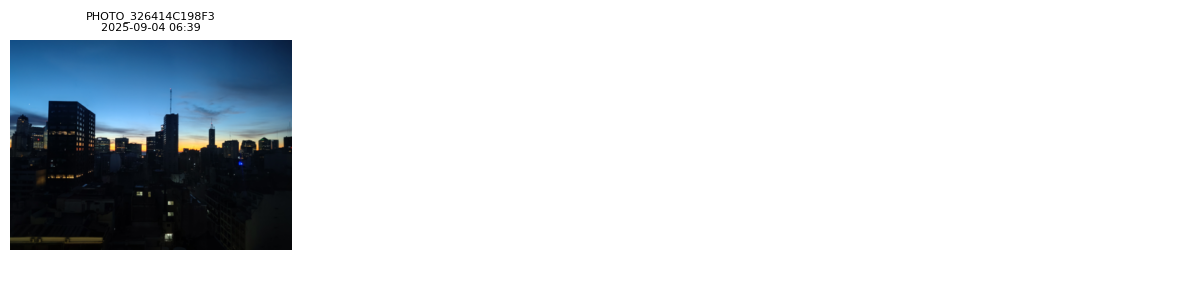

In [37]:
# Displaying one suggested session for checking the photographs
if not session_summary.empty:
    show_session(session_summary.iloc[0]["suggested_session"])

### Creating the session review file

In [38]:
# Selecting the information needed for manual review
review = sessions[["photo_id",
        "location",
        "original_filename",
        "relative_path",
        "capture_time",
        "suggested_session"]].copy()

# Copying suggested IDs for manual correction
review["session_id"] = review["suggested_session"]

# Creating a column for closely related photographs
review["related_group"] = ""

# Setting the location of the review draft
review_file = metadata / "session_review_draft.csv"

# Checking whether an earlier review draft exists
if review_file.exists():
    old = pd.read_csv(review_file, keep_default_na=False)

    # Comparing photograph IDs, locations, and paths
    columns = ["photo_id", "location", "relative_path"]

    old_check = (
        old[columns]
        .sort_values("photo_id")
        .reset_index(drop=True))

    new_check = (
        review[columns]
        .sort_values("photo_id")
        .reset_index(drop=True))

    if not old_check.equals(new_check):
        raise ValueError(
            "The saved review draft does not match the current inventory.")

    print("Keeping the existing review draft:", review_file)

else:
    # Saving the draft without overwriting previous work
    review.to_csv(review_file, index=False)
    print("Review draft saved:", review_file)

Keeping the existing review draft: /content/drive/MyDrive/CS156_Photographic_Eye/02_metadata/session_review_draft.csv


### Loading the reviewed sessions

In [39]:
# Setting the location of my manually reviewed CSV
review_file = metadata / "session_review_draft.csv"

# Checking that the reviewed file exists
if not review_file.is_file():
    raise FileNotFoundError(
        "The reviewed session_review_draft.csv file was not found.")

# Loading my final session and related-group assignments
final_sessions = pd.read_csv(
    review_file,
    keep_default_na=False)

# Removing extra spaces from the reviewed IDs
for column in ["photo_id", "session_id", "related_group"]:
    final_sessions[column] = (
        final_sessions[column]
        .astype(str)
        .str.strip())

# Confirming the reviewed file and related-image assignments
print("Reviewed file loaded:", review_file)
print("Photographs in related groups:",
    (final_sessions["related_group"] != "").sum())

Reviewed file loaded: /content/drive/MyDrive/CS156_Photographic_Eye/02_metadata/session_review_draft.csv
Photographs in related groups: 522


### Checking final session assignments

In [40]:
# Checking that photograph IDs are not repeated
if final_sessions["photo_id"].duplicated().any():
    raise ValueError("Some photograph IDs appear more than once.")

# Selecting the original image information for checking
columns = ["photo_id", "location", "relative_path"]

# Sorting both tables for comparing the same photographs
original = (
    inventory[columns]
    .sort_values("photo_id")
    .reset_index(drop=True))

reviewed = (
    final_sessions[columns]
    .sort_values("photo_id")
    .reset_index(drop=True))

# Checking that no photographs or original paths were changed
if not original.equals(reviewed):
    raise ValueError(
        "The reviewed file does not match the original inventory.")

# Checking that every photograph has a session ID
if final_sessions["session_id"].eq("").any():
    raise ValueError("Some photographs still need a session ID.")

# Checking that each session belongs to one location
session_locations = (
    final_sessions.groupby("session_id")["location"].nunique())

if (session_locations > 1).any():
    raise ValueError(
        "A session ID appears in multiple locations.")

# Selecting photographs assigned to related-image groups
related = final_sessions[
    final_sessions["related_group"] != ""]

# Counting the sessions represented in each related group
related_sessions = (
    related.groupby("related_group")["session_id"].nunique())

# Checking whether related photographs belong to different sessions
if (related_sessions > 1).any():

    # Finding related groups that need correction
    wrong_groups = related_sessions[
        related_sessions > 1
    ].index

    # Selecting photographs with conflicting assignments
    wrong = related[
        related["related_group"].isin(wrong_groups)]

    # Displaying the photographs that need manual correction
    display(
        wrong[
            ["photo_id", "location", "session_id", "related_group"]
        ].sort_values(["related_group", "session_id"]))

    raise ValueError(
        "Some related-image groups contain different session IDs.")

### Saving the final session information

In [41]:
# Combining reviewed sessions with the original image inventory
session_data = inventory.merge(
    final_sessions[
        ["photo_id", "session_id", "related_group"]
    ],
    on="photo_id",
    validate="one_to_one")

# Setting the location of the final session file
session_file = metadata / "session_metadata.csv"

# Saving completed sessions with the original image information
session_data.to_csv(session_file, index=False)

# Counting photography sessions within each location
session_counts = (
    session_data.groupby("location")["session_id"]
    .nunique()
    .reset_index(name="sessions"))

# Displaying the final session coverage
display(session_counts)

# Printing the saved file location
print("Session metadata saved:", session_file)

,location,sessions
0,Argentina,32
1,Berlin,16
2,Korea,31
3,Poland,8
4,Taiwan,30


Session metadata saved: /content/drive/MyDrive/CS156_Photographic_Eye/02_metadata/session_metadata.csv


# Appendix C: Random Candidate Sampling

I am randomly selecting 35 eligible photographs from each location before assigning portfolio labels. Here, I will use a fixed random seed so the same photographs are selected when the notebook runs again.
<br> <br>
I keep the session and related-image information from Appendix B and similar photographs can remain because differences in composition may affect my portfolio choices.
<br> <br>
Then, I will judge photographs visually without using filenames, dates, or session information to influence my decisions. If a location needs more examples of either class after labeling, I will select 10 more unused photographs from the same random order. Previous labels will remain unchanged.

### Loading the completed session information

In [42]:
# Loading the completed session information from Appendix B
sample_data = pd.read_csv(
    session_file,
    keep_default_na=False)

# Defining the five locations included in my study
locations = [
    "Argentina",
    "Berlin",
    "Korea",
    "Poland",
    "Taiwan"]

# Counting eligible photographs in each location
counts = sample_data["location"].value_counts()

# Checking that all five locations are included
if set(counts.index) != set(locations):
    raise ValueError(
        "The locations do not match the planned dataset.")

# Checking that each location has at least 35 photographs
if (counts.reindex(locations) < 35).any():
    raise ValueError(
        "A location has fewer than 35 eligible photographs.")

### Creating a fixed random sampling order

In [43]:
# Sorting photographs before creating a repeatable random order
pool = sample_data.sort_values(
    ["location", "photo_id"]).copy()

# Shuffling photographs separately within each location
pool = (
    pool.groupby("location", group_keys=False)
    .sample(frac=1, random_state=156)
    .copy())

# Numbering the random order within each location
pool["draw_order"] = (
    pool.groupby("location").cumcount() + 1)

### Creating the candidate review file

In [44]:
# Setting the location of the candidate review file
candidate_file = metadata / "candidate_review.csv"

# Creating the initial sample only when no saved file exists
if not candidate_file.exists():

    # Selecting the first 35 random photographs per location
    first = pool[
        pool["draw_order"] <= 35
    ].copy()

    # Recording the first sampling batch
    first["batch"] = 1

    # Creating empty columns for manual labeling
    first["selected"] = ""
    first["uncertain"] = ""

    # Selecting the information needed for reviewing candidates
    keep = [
        "photo_id",
        "location",
        "original_filename",
        "relative_path",
        "capture_time",
        "session_id",
        "related_group",
        "draw_order",
        "batch",
        "selected",
        "uncertain"]

    # Saving candidates without overwriting previous work
    first[keep].sort_values(["location", "draw_order"]).to_csv(candidate_file, index=False)

### Checking the saved candidates

In [45]:
# Loading the saved candidate review file
candidates = pd.read_csv(
    candidate_file,
    keep_default_na=False)

# Checking that the necessary columns are included
needed = [
    "photo_id",
    "location",
    "relative_path",
    "session_id",
    "related_group",
    "draw_order",
    "batch",
    "selected",
    "uncertain"]

if not set(needed).issubset(candidates.columns):
    raise ValueError(
        "The candidate review file is missing required columns.")

# Checking that no photograph was selected twice
if candidates["photo_id"].duplicated().any():
    raise ValueError(
        "Some sampled photographs appear more than once.")

# Selecting the original information for checking
columns = ["photo_id",
    "location",
    "relative_path",
    "session_id",
    "related_group",
    "draw_order"]

# Finding the saved photographs in the original random order
current = pool[
    pool["photo_id"].isin(candidates["photo_id"])]

# Sorting both tables for comparing the same photographs
original = (current[columns]
    .sort_values("photo_id")
    .reset_index(drop=True))

saved = (candidates[columns]
    .sort_values("photo_id")
    .reset_index(drop=True))

# Checking that saved candidates match the original random order
if not original.equals(saved):
    raise ValueError(
        "The saved candidates do not match the current random order.")

# Checking that no random positions are missing
for location in locations:

    draws = sorted(
        candidates.loc[
            candidates["location"] == location,
            "draw_order"
        ].tolist())

    if len(draws) < 35 or draws != list(range(1, len(draws) + 1)):
        raise ValueError(
            f"The candidate order is incomplete for {location}.")

# Counting sampled photographs within each location
candidate_counts = (candidates.groupby("location").size()
    .reset_index(name="candidates"))

# Displaying the candidate counts
display(candidate_counts)

# Printing the saved candidate file location
print("Candidate review file:", candidate_file)

,location,candidates
0,Argentina,35
1,Berlin,35
2,Korea,35
3,Poland,35
4,Taiwan,35


Candidate review file: /content/drive/MyDrive/CS156_Photographic_Eye/02_metadata/candidate_review.csv


### Reviewing candidate photographs

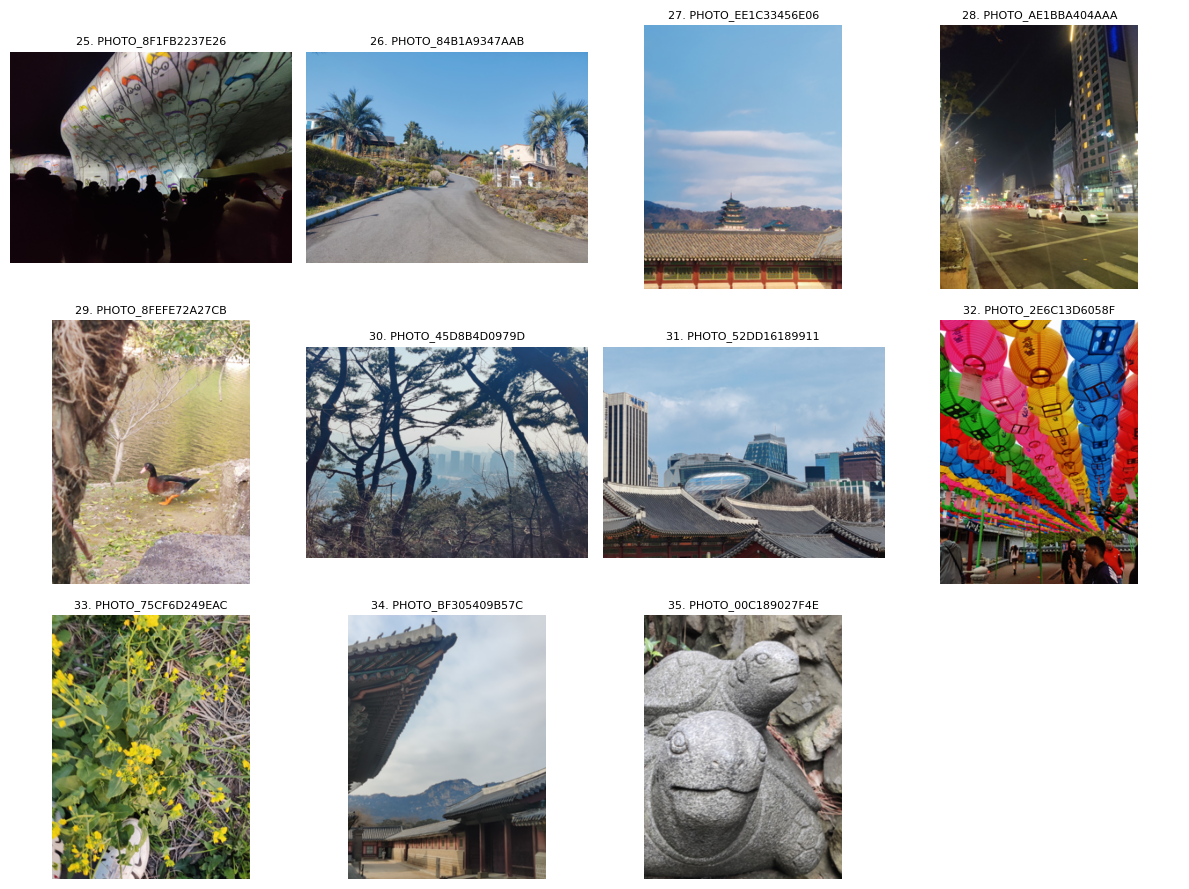

In [46]:
# Creating a function for displaying sampled photographs
def show_candidates(location, start=0, number=12):

    # Selecting photographs from the requested location
    group = (
        candidates[candidates["location"] == location]
        .sort_values("draw_order")
        .iloc[start:start + number])

    # Checking whether photographs were found
    if group.empty:
        print("No photographs found.")
        return

    # Calculating the number of display rows
    columns = 4
    rows = (len(group) + columns - 1) // columns

    # Creating the photograph display
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(12, 3 * rows),
        squeeze=False)

    # Hiding unnecessary plot markings
    for ax in axes.flat:
        ax.axis("off")

    # Displaying each photograph with its ID
    for ax, (_, photo) in zip(axes.flat, group.iterrows()):

        path = project / photo["relative_path"]

        with Image.open(path) as img:

            # Correcting rotation and preparing a smaller preview
            picture = ImageOps.exif_transpose(img).convert("RGB")
            picture.thumbnail((400, 300))
            ax.imshow(picture)

        # Showing the random position and photograph ID
        ax.set_title(
            f"{photo['draw_order']}. {photo['photo_id']}",
            fontsize=8)

    plt.tight_layout()
    plt.show()


# Displaying the first 12 candidates from a country
show_candidates("Korea", start=24, number=11)

# Appendix D: Checking Manual Portfolio Labels

I am checking my manual portfolio labels before selecting the final photographs. My judgment is based on the original image, without considering cropping, straightening, or other edits. I will only use confident judgments for the final dataset and keep uncertain judgments in the original review file.
<br> <br>
Then, I will randomly select 10 portfolio-worthy and 10 non-portfolio-worthy photographs from each location. This will give me 100 photographs with equal class counts across the five locations.

### Checking labels and counting results

In [47]:
# Loading my latest manual labels from the saved review file
candidates = pd.read_csv(
    candidate_file,
    keep_default_na=False)

# Removing extra spaces from my manual labels
for column in ["selected", "uncertain"]:
    candidates[column] = (
        candidates[column].astype(str).str.strip())

# Checking that every photograph has valid labels
for column in ["selected", "uncertain"]:
    if not candidates[column].isin(["0", "1"]).all():
        raise ValueError(
            f"Some photographs have missing or incorrect {column} values.")

# Selecting photographs with confident judgments
confident = candidates[
    candidates["uncertain"] == "0"]

# Counting confident positive and negative labels by location
label_counts = (
    confident.groupby(["location", "selected"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={
        "0": "not_selected",
        "1": "selected"})
    .reindex(
        index=locations,
        columns=["not_selected", "selected"],
        fill_value=0))

# Counting uncertain judgments separately
label_counts["uncertain"] = (
    candidates["uncertain"].eq("1")
    .groupby(candidates["location"])
    .sum()
    .reindex(locations, fill_value=0))

# Checking which locations need more photographs
label_counts["needs_more"] = (
    label_counts[["not_selected", "selected"]] < 10).any(axis=1)

# Displaying the manual labeling results
display(label_counts)

selected,not_selected,selected,uncertain,needs_more
location,,,,
Argentina,10,19,6,False
Berlin,19,11,5,False
Korea,13,12,10,False
Poland,15,11,9,False
Taiwan,17,14,4,False


### Selecting the final photographs

In [48]:
# Checking that each location has enough photographs
if label_counts["needs_more"].any():
    raise ValueError(
        "Some locations need more photographs before final selection.")

# Selecting photographs with confident portfolio labels
ready = candidates[
    candidates["uncertain"] == "0"].copy()

# Randomly selecting 10 photographs from each class and location
final_data = (
    ready.sort_values("photo_id")
    .groupby(["location", "selected"], group_keys=False)
    .sample(n=10, random_state=156)
    .sort_values(["location", "selected", "photo_id"])
    .reset_index(drop=True))

# Creating the folder for saving the final dataset
final_folder = project / "03_final_dataset"
final_folder.mkdir(parents=True, exist_ok=True)

# Setting the location of the final dataset file
final_file = final_folder / "final_photo_metadata.csv"

# Saving the final selection without overwriting previous work
if not final_file.exists():
    final_data.to_csv(final_file, index=False)

# Loading the saved selection for checking
saved = pd.read_csv(
    final_file,
    keep_default_na=False,
    dtype={"selected": str, "uncertain": str})

# Selecting the original information for comparison
columns = [
    "photo_id",
    "location",
    "selected",
    "uncertain",
    "relative_path",
    "session_id",
    "related_group",
    "draw_order"]

# Sorting both tables for comparing the same photographs
original = (
    final_data[columns]
    .sort_values("photo_id")
    .reset_index(drop=True))

reviewed = (
    saved[columns]
    .sort_values("photo_id")
    .reset_index(drop=True))

# Checking that the saved photographs match the final selection
if not original.equals(reviewed):
    raise ValueError(
        "The saved final dataset does not match the current selection.")

# Counting the final photographs by location and class
final_counts = (saved.groupby(["location", "selected"]).size().unstack(fill_value=0))

# Displaying the final photograph counts
display(final_counts)

# Printing the saved dataset location
print("Final dataset saved:", final_file)

selected,0,1
location,,
Argentina,10,10
Berlin,10,10
Korea,10,10
Poland,10,10
Taiwan,10,10


Final dataset saved: /content/drive/MyDrive/CS156_Photographic_Eye/03_final_dataset/final_photo_metadata.csv


# Appendix E: Checking the Development and Test Sets

Berlin will be reserved as the final test location, while photographs from the other four locations will be used for model development and cross-validation.
<br> <br>
Before training, I will check the photography sessions to make sure no session appears in both sets. I will also compare three-fold and four-fold cross-validation to determine which approach gives more consistent validation sets.
<br> <br>
The Berlin photographs will remain separate throughout model training and tuning, and will only be used for the final evaluation.

### Checking the location and photography sessions

In [49]:
# Loading the final photographs saved in Appendix D
data = pd.read_csv(
    final_file,
    keep_default_na=False,
    dtype={"selected": str})

# Checking that the final dataset has 100 unique photographs
if len(data) != 100 or data["photo_id"].duplicated().any():
    raise ValueError(
        "The final dataset must contain 100 different photographs.")

# Checking that every photograph has a session
if data["session_id"].eq("").any():
    raise ValueError(
        "Some photographs are missing a session.")

# Setting Berlin aside for the final test
test_location = "Berlin"

# Separating development and test photographs
dev = data[data["location"] != test_location].copy()
test = data[data["location"] == test_location].copy()

# Checking the expected number of photographs
if len(dev) != 80 or len(test) != 20:
    raise ValueError(
        "The development or test set has an unexpected size.")

# Checking that no session appears in both sets
if set(dev["session_id"]) & set(test["session_id"]):
    raise ValueError(
        "A photography session appears in both sets.")

# Counting selected and non-selected photographs in each session
per_session = (
    data.groupby(["location", "session_id", "selected"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["0", "1"], fill_value=0)
    .reset_index()
    .rename(columns={
        "0": "not_selected",
        "1": "selected"}))

# Calculating the number of photographs in each session
per_session["total"] = (
    per_session["not_selected"] + per_session["selected"])

# Summarizing session information for each location
session_check = []

for location in locations:

    part = per_session[
        per_session["location"] == location]

    session_check.append({
        "location": location,
        "photographs": part["total"].sum(),
        "sessions": len(part),
        "sessions_with_0": (part["not_selected"] > 0).sum(),
        "sessions_with_1": (part["selected"] > 0).sum(),
        "largest_session": part["total"].max()})

# Displaying the session information
display(pd.DataFrame(session_check))

,location,photographs,sessions,sessions_with_0,sessions_with_1,largest_session
0,Argentina,20,11,5,8,5
1,Berlin,20,11,8,5,5
2,Korea,20,12,9,6,6
3,Poland,20,5,4,4,7
4,Taiwan,20,8,5,5,10


### Checking four-fold cross-validation

In [50]:
from sklearn.model_selection import StratifiedGroupKFold

# Creating temporary four-fold splits to examine their distributions
cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=156)

# Saving the same folds for comparing all models later
folds = list(
    cv.split(
        dev,
        dev["selected"],
        groups=dev["session_id"]))

# Creating a list for checking each fold
results = []

for number, (train_idx, val_idx) in enumerate(folds, start=1):

    # Selecting the training and validation photographs
    train_part = dev.iloc[train_idx]
    val_part = dev.iloc[val_idx]

    # Checking that no session appears in both sets
    if set(train_part["session_id"]) & set(val_part["session_id"]):
        raise ValueError(
            "A photography session appears in both sets.")

    # Counting photographs, labels, and sessions in each fold
    results.append({
        "fold": number,
        "train_photos": len(train_part),
        "val_photos": len(val_part),
        "train_0": (train_part["selected"] == "0").sum(),
        "train_1": (train_part["selected"] == "1").sum(),
        "val_0": (val_part["selected"] == "0").sum(),
        "val_1": (val_part["selected"] == "1").sum(),
        "val_sessions": val_part["session_id"].nunique(),
        "val_locations": val_part["location"].nunique(),
        "largest_session": val_part["session_id"].value_counts().max()})

# Displaying the fold information for review
fold_table = pd.DataFrame(results)
display(fold_table)

# Checking that training and validation contain both classes
label_columns = ["train_0", "train_1", "val_0", "val_1"]

if (fold_table[label_columns] == 0).any().any():
    raise ValueError(
        "At least one fold is missing a class.")

,fold,train_photos,val_photos,train_0,train_1,val_0,val_1,val_sessions,val_locations,largest_session
0,1,72,8,37,35,3,5,6,4,3
1,2,56,24,28,28,12,12,11,4,10
2,3,57,23,30,27,10,13,11,4,5
3,4,55,25,25,30,15,10,8,4,7


### Checking three-fold cross-validation

In [51]:
from sklearn.model_selection import StratifiedGroupKFold

# Creating three folds while keeping photography sessions together
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=156)

# Saving the same folds for comparing all models later
folds = list(
    cv.split(
        dev,
        dev["selected"],
        groups=dev["session_id"]))

# Creating a list for checking each fold
results = []

for number, (train_idx, val_idx) in enumerate(folds, start=1):

    # Selecting the training and validation photographs
    train_part = dev.iloc[train_idx]
    val_part = dev.iloc[val_idx]

    # Checking that no session appears in both sets
    if set(train_part["session_id"]) & set(val_part["session_id"]):
        raise ValueError(
            "A photography session appears in both sets.")

    # Counting photographs, labels, and sessions in each fold
    results.append({
        "fold": number,
        "train_photos": len(train_part),
        "val_photos": len(val_part),
        "train_0": (train_part["selected"] == "0").sum(),
        "train_1": (train_part["selected"] == "1").sum(),
        "val_0": (val_part["selected"] == "0").sum(),
        "val_1": (val_part["selected"] == "1").sum(),
        "val_sessions": val_part["session_id"].nunique(),
        "val_locations": val_part["location"].nunique(),
        "largest_session": val_part["session_id"].value_counts().max()})

# Displaying the fold information for review
fold_table = pd.DataFrame(results)
display(fold_table)

# Checking that training and validation contain both classes
label_columns = ["train_0", "train_1", "val_0", "val_1"]

if (fold_table[label_columns] == 0).any().any():
    raise ValueError(
        "At least one fold is missing a class.")

,fold,train_photos,val_photos,train_0,train_1,val_0,val_1,val_sessions,val_locations,largest_session
0,1,51,29,27,24,13,16,14,4,5
1,2,57,23,27,30,13,10,10,4,10
2,3,52,28,26,26,14,14,12,4,7


### Final Cross-Validation Decision

Three-fold StratifiedGroupKFold was selected after comparing the session distributions under three and four folds. The four-fold approach produced one particularly small validation set of just 8 photographs, making its performance estimate sensitive to individual prediction errors.
<br> <br>

With three folds, validation sizes range from 23 to 29 photographs and every fold contains both labels, 10–14 photography sessions, and photographs from all four development locations. Additionally, sessions remain separate between training and validation to reduce the risk of overly optimistic results from similar images.
<br> <br>
One limitation is that a single Taiwan session contributes 10 of the 23 photographs in Fold 2. Despite this concentration, the three-fold design provides more consistent validation sets. These fixed folds will be used for every model comparison, while Berlin remains reserved for the final evaluation.

# Appendix F: Exploring Dataset Characteristics and Potential Biases

Before training the models, I want to examine whether technical and visual differences between photographs are associated with my portfolio selections. Differences in image orientation, resolution, lighting, and color could influence model predictions.
<br> <br>
These checks will use only the 80 development photographs, keeping Berlin separate for final evaluation. My goal is to identify patterns worth investigating, not to assume that every difference represents bias. Some characteristics, such as color and composition, may genuinely contribute to my photographic preferences.

### Checking camera models, orientation, and resolution

In [52]:
# Loading image details saved in Appendix B
image_data = pd.read_csv(
    session_file,
    keep_default_na=False)

# Selecting the image details needed for comparison
columns = [
    "photo_id",
    "width",
    "height",
    "orientation",
    "camera_model"]

# Matching image details to the development photographs
image_info = dev.merge(
    image_data[columns],
    on="photo_id",
    how="left",
    validate="one_to_one")

# Converting image dimensions into numbers
for column in ["width", "height"]:
    image_info[column] = pd.to_numeric(
        image_info[column],
        errors="coerce")

# Checking for missing or invalid image dimensions
if image_info[["width", "height"]].isna().any().any():
    raise ValueError("Some image dimensions are missing.")

if (image_info[["width", "height"]] <= 0).any().any():
    raise ValueError("Some image dimensions are invalid.")

# Calculating image resolution in megapixels
image_info["megapixels"] = (
    image_info["width"] * image_info["height"] / 1_000_000)

# Marking cameras without recorded model information
image_info["camera_model"] = image_info["camera_model"].replace(
    "", "Unknown")

# Comparing image resolution between the two labels
resolution_table = (
    image_info.groupby("selected")
    .agg(median_megapixels=("megapixels", "median"))
.rename(index={
        "0": "Not selected",
        "1": "Selected"})
    .round(2))

print("Image resolution by label:")
display(resolution_table)

# Counting image orientations within each label
orientation_table = pd.crosstab(
    image_info["orientation"],
    image_info["selected"]
).reindex(columns=["0", "1"], fill_value=0)

orientation_table.columns = ["Not selected", "Selected"]

# Calculating the percentage selected within each orientation
orientation_table["Selected (%)"] = (
    100 * orientation_table["Selected"]
    / orientation_table.sum(axis=1)
).round(1)

print("Image orientation by label:")
display(orientation_table)

# Counting photographs from each camera model
camera_table = pd.crosstab(
    image_info["camera_model"],
    image_info["selected"]
).reindex(columns=["0", "1"], fill_value=0)

camera_table.columns = ["Not selected", "Selected"]
camera_table["Total"] = camera_table.sum(axis=1)

# Calculating the percentage selected within each camera model
camera_table["Selected (%)"] = (
    100 * camera_table["Selected"] / camera_table["Total"]
).round(1)

print("Camera models by label:")
display(camera_table.sort_values("Total", ascending=False))

Image resolution by label:


,median_megapixels
selected,
Not selected,12.0
Selected,12.0


Image orientation by label:


,Not selected,Selected,Selected (%)
orientation,,,
landscape,18,13,41.9
portrait,14,20,58.8
square,8,7,46.7


Camera models by label:


,Not selected,Selected,Total,Selected (%)
camera_model,,,,
KB2005,40,40,80,50.0


### Measuring Basic Visual Properties

In [53]:
import numpy as np

# Creating a list for saving image measurements
measurements = []

# Measuring each development photograph
for _, photo in image_info.iterrows():

    path = project / photo["relative_path"]

    with Image.open(path) as img:

        # Correcting rotation and keeping image proportions
        picture = ImageOps.exif_transpose(img).convert("RGB")
        picture.thumbnail((256, 256))

        # Converting pixel values to numbers between 0 and 1
        pixels = np.asarray(
            picture,
            dtype=np.float32) / 255.0

        # Calculating grayscale brightness
        gray = (
            0.2126 * pixels[:, :, 0]
            + 0.7152 * pixels[:, :, 1]
            + 0.0722 * pixels[:, :, 2])

        # Measuring color saturation
        hsv = np.asarray(
            picture.convert("HSV"),
            dtype=np.float32)

        saturation = hsv[:, :, 1] / 255.0

        # Saving the three image measurements
        measurements.append({
            "photo_id": photo["photo_id"],
            "brightness": gray.mean(),
            "contrast": gray.std(),
            "saturation": saturation.mean()})

# Combining measurements with development information
visual_info = image_info.merge(
    pd.DataFrame(measurements),
    on="photo_id",
    validate="one_to_one")

# Comparing visual properties between the two labels
visual_table = (
    visual_info.groupby("selected")
    .agg(
        brightness=("brightness", "median"),
        contrast=("contrast", "median"),
        saturation=("saturation", "median"))
    .rename(index={
        "0": "Not selected",
        "1": "Selected"})
    .round(3))

print("Visual properties by label:")
display(visual_table)

# Comparing visual properties within each location
location_table = (
    visual_info.groupby(["location", "selected"])[
        ["brightness", "contrast", "saturation"]]
    .median()
    .round(3))

print("Visual properties by location and label:")
display(location_table)

Visual properties by label:


,brightness,contrast,saturation
selected,,,
Not selected,0.483,0.207,0.297
Selected,0.441,0.199,0.326


Visual properties by location and label:


brightness  contrast  saturation
location  selected                                  
Argentina 0              0.471     0.206       0.352
          1              0.452     0.198       0.328
Korea     0              0.506     0.190       0.281
          1              0.411     0.194       0.265
Poland    0              0.483     0.223       0.267
          1              0.480     0.216       0.249
Taiwan    0              0.449     0.195       0.300
          1              0.437     0.201       0.507

### Interpreting the Results

All 80 development photographs came from the same recorded camera model (KB2005). Both selected and non-selected photographs had a median resolution of 12 megapixels.
<br> <br>
Portrait photographs had a higher selection percentage than landscape photographs. Selected photographs also had slightly lower median brightness and contrast.
<br> <br>
Selected photographs had higher median saturation overall. However, this pattern differed across locations. In Taiwan, selected photographs had much higher median saturation than non-selected photographs. In the other three development locations, selected photographs had slightly lower median saturation.
<br> <br>
These findings suggest that simple visual characteristics may be associated with my portfolio decisions. However, these differences do not establish causation or prove that the dataset is biased. I therefore kept my original labels, final dataset, and three-fold cross-validation unchanged.

## 9. References

Chilamkurthy, S. (2025, January 27). *Transfer learning for computer vision tutorial*. PyTorch. https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

Graphviz. (n.d.). *User guide*. https://graphviz.readthedocs.io/en/stable/manual.html

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770–778). https://doi.org/10.1109/CVPR.2016.90

Pillow. (n.d.). *ImageOps module*. https://pillow.readthedocs.io/en/stable/reference/ImageOps.html

Pillow-Heif. (n.d.). *Pillow-Heif documentation*. https://pillow-heif.readthedocs.io/en/latest/

Python Software Foundation. (n.d.). *hashlib — Secure hashes and message digests*. https://docs.python.org/3/library/hashlib.html

PyTorch. (n.d.). *resnet18*. https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html

Scikit-learn developers. (n.d.-a). *balanced_accuracy_score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html

Scikit-learn developers. (n.d.-b). *Common pitfalls and recommended practices*. https://scikit-learn.org/stable/common_pitfalls.html

Scikit-learn developers. (n.d.-c). *LogisticRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

Scikit-learn developers. (n.d.-d). *PCA*. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

Scikit-learn developers. (n.d.-e). *StratifiedGroupKFold*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html

### 10 AI Statement
I used ChatGPT for initial assignment mindmapping and then used Gemni in Google Colab to help me figure out the coding errors and even help me come up with better approaches for the code implimentation.

Here's my chat: https://chatgpt.com/share/6ad64ba9-ccb0-83eb-984c-e09c2a1603e8

